# Task 17 — Practical Deep Learning Defaults & Custom Models and Training with TensorFlow

**Prepared by:** Elavarasu K  |  **Date:** 15/10/2026  |  **Track:** ML track (Task 16 → Task 17)

> **Goal.** Finish the deep-network toolkit with sensible *default configurations* (and the exceptions to them), then go below `fit()`: use TensorFlow's low-level API to write custom losses, metrics, layers, models, gradients and full training loops — and speed them up with TF Functions and graphs.

### How to read this notebook
Each phase follows one pattern: **a short plain-English idea → a real-life example → code you can run → what the result tells us**. The README tasks are numbered here as *Task 1.1, 1.2 …* so you can match them line by line.

| Phase | Topic |
|---|---|
| 1 | Default DNN configurations, the three exceptions, the seven review questions |
| 2 | A quick tour of TensorFlow — using it like NumPy |
| 3 | Custom loss functions (Huber) and saving custom components |
| 4 | Custom activations, initializers, regularizers, constraints and (streaming) metrics |
| 5 | Custom layers, custom models and losses based on model internals |
| 6 | Computing gradients with autodiff (`GradientTape`) |
| 7 | Custom training loops |
| 8 | TF Functions, graphs, and the two capstones (LayerNorm clone, two-optimizer loop) |
| Exercises | All 13 exercises |

### Three honest notes before we start
1. **Library versions.** The README was written for TensorFlow 2.0-era `tf.keras`; this notebook runs on the **current Keras 3**. The few places where the old snippets break are fixed and flagged with *"Keras 3 note"*: `learning_rate=` (not `lr=`), `reset_state()` (not `reset_states()`), `add_weight()` takes keyword arguments, `add_metric()` was removed (a `keras.metrics.Mean` attribute does the same job), `Dense`-style layers get a plain tuple in `build()`, saving uses the `.keras` format, and `Lambda` layers need `safe_mode=False` to load.
2. **CIFAR10 → Fashion MNIST.** Exercises 1–4 ask for CIFAR10. The CIFAR10 download host could not be reached when this notebook was executed, so the executed outputs use **Fashion MNIST** (the same kind of task: 10 image classes). One switch, `DATASET = "cifar10"` in the exercise section, runs the very same code on CIFAR10.
3. **Run time.** The full notebook runs in roughly 40–60 minutes on a laptop CPU. `EPOCH_SCALE` (next cell) shrinks every training run for a quick dry run.

In [1]:
import os, time, math, gzip, functools, warnings, datetime, urllib.request
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"            # hide TensorFlow's start-up chatter
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import display
import logging
for _name in ("tensorflow", "absl", ""): logging.getLogger(_name).setLevel(logging.ERROR)
tf.get_logger().setLevel("ERROR")

print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| NumPy", np.__version__)

SEED = 42
def reset_seed(seed=SEED):
    keras.utils.set_random_seed(seed)       # python + numpy + tensorflow seeds
reset_seed()

# EPOCH_SCALE shrinks every training run (use 0.1 for a quick dry run, 1.0 for the real thing)
EPOCH_SCALE = 1.0
def ep(n):
    return max(1, int(round(n * EPOCH_SCALE)))

plt.rcParams.update({"figure.figsize": (7.5, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

TensorFlow 2.21.0 | Keras 3.15.1 | NumPy 2.5.3


### Data used in this notebook

The same two datasets as Task 16, downloaded once into a local `data/` folder:

* **California Housing** (your Task 1 `housing.csv`, turned into the 8 classic numeric features; the target is the price in units of $100,000). Used for Phases 3–7 (a regression problem is the natural place to test Huber loss, metrics and custom layers).
* **Fashion MNIST** (70,000 grey 28×28 clothing images, 10 classes). Used for Phase 1 demos, Phase 8 and the exercises.

Pre-processing for housing: split 60 % / 20 % / 20 % into train / validation / test, **standardize with the training-set mean and standard deviation only** (so nothing leaks from validation/test), and clip standardized values to ±5σ (a few extreme districts would otherwise produce huge inputs).

In [2]:
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)
FMNIST_URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
FMNIST_FILES = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz", "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]
HOUSING_URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

def _read_idx(path, images):
    with gzip.open(path, "rb") as f:
        buf = f.read()
    return np.frombuffer(buf, np.uint8, offset=16).reshape(-1, 28, 28) if images else np.frombuffer(buf, np.uint8, offset=8)

def load_fashion_mnist():
    try:
        for name in FMNIST_FILES:
            path = os.path.join(DATA_DIR, name)
            if not os.path.exists(path): urllib.request.urlretrieve(FMNIST_URL + name, path)
        p = lambda n: os.path.join(DATA_DIR, n)
        return ((_read_idx(p(FMNIST_FILES[0]), True), _read_idx(p(FMNIST_FILES[1]), False)),
                (_read_idx(p(FMNIST_FILES[2]), True), _read_idx(p(FMNIST_FILES[3]), False)))
    except Exception as e:
        print("GitHub download failed (", e, ") -> using keras.datasets.fashion_mnist")
        return keras.datasets.fashion_mnist.load_data()

def load_housing():
    path = os.path.join(DATA_DIR, "housing.csv")
    try:
        if not os.path.exists(path): urllib.request.urlretrieve(HOUSING_URL, path)
        df = pd.read_csv(path)
        df["total_bedrooms"] = df["total_bedrooms"].fillna(df["total_bedrooms"].median())
        X = pd.DataFrame({"MedInc": df["median_income"], "HouseAge": df["housing_median_age"],
                          "AveRooms": df["total_rooms"] / df["households"], "AveBedrms": df["total_bedrooms"] / df["households"],
                          "Population": df["population"], "AveOccup": df["population"] / df["households"],
                          "Latitude": df["latitude"], "Longitude": df["longitude"]})
        return X.values.astype("float32"), (df["median_house_value"] / 100_000).values.astype("float32")
    except Exception as e:
        print("housing.csv download failed (", e, ") -> using sklearn.fetch_california_housing")
        from sklearn.datasets import fetch_california_housing
        h = fetch_california_housing(); return h.data.astype("float32"), h.target.astype("float32")

# ---- housing ----
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
X_h, y_h = load_housing()
X_tr0, X_te0, y_train_h, y_test_h = train_test_split(X_h, y_h, test_size=0.2, random_state=42)
X_tr0, X_va0, y_train_h, y_valid_h = train_test_split(X_tr0, y_train_h, test_size=0.25, random_state=42)
y_train_h, y_valid_h, y_test_h = [a.reshape(-1, 1) for a in (y_train_h, y_valid_h, y_test_h)]       # targets as columns, shape (n, 1), like the model output
scaler = StandardScaler().fit(X_tr0)
X_train_h, X_valid_h, X_test_h = [np.clip(scaler.transform(a), -5, 5).astype("float32") for a in (X_tr0, X_va0, X_te0)]
print("housing: train", X_train_h.shape, "| validation", X_valid_h.shape, "| test", X_test_h.shape)

# ---- fashion mnist ----
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
(X_full, y_full), (X_test, y_test) = load_fashion_mnist()
X_train, y_train = X_full[:-5000] / 255.0, y_full[:-5000]
X_valid, y_valid = X_full[-5000:] / 255.0, y_full[-5000:]
X_train, X_valid, X_test = [a.astype("float32") for a in (X_train, X_valid, X_test / 255.0)]
print("fashion mnist: train", X_train.shape, "| validation", X_valid.shape, "| test", X_test.shape)

def housing_mlp(loss="mse", metrics=None, lr=0.002, hidden=(30, 30)):
    # a small reference regressor used all through Phases 3-7
    net = keras.Sequential([layers.Input((8,))] + [layers.Dense(n, activation="relu", kernel_initializer="he_normal") for n in hidden] + [layers.Dense(1)])
    net.compile(loss=loss, optimizer=keras.optimizers.Nadam(learning_rate=lr), metrics=metrics or [])
    return net

def mae_mse(net, X=None, y=None):
    X = X_test_h if X is None else X; y = y_test_h if y is None else y
    p = net.predict(X, verbose=0, batch_size=2048).ravel(); y = y.ravel()
    return float(np.mean(np.abs(p - y))), float(np.mean((p - y) ** 2))

housing: train (12384, 8) | validation (4128, 8) | test (4128, 8)


fashion mnist: train (55000, 28, 28) | validation (5000, 28, 28) | test (10000, 28, 28)


---
# Phase 1 — Default DNN Configurations & Practical Guidelines

**Simple idea.** Task 16 gave you many knobs (initializer, activation, normalization, optimizer, schedule…). Beginners drown in the choices. A **default configuration** is a recipe that works well in most cases with almost no tuning, plus a short list of situations where you should deviate. Think of it as the "house recipe" at a restaurant: great without changes, but you adjust it when the guest has an allergy.

### Task 1.1 — The default DNN configuration

| Hyperparameter | Default DNN | Self-normalizing net |
|---|---|---|
| Kernel initializer | **He** | **LeCun** |
| Activation | **ELU** | **SELU** |
| Normalization | None if shallow; **Batch Norm** if deep | None (it normalizes itself) |
| Regularization | **Early stopping** (+ ℓ2 if needed) | **Alpha dropout** if needed |
| Optimizer | **Momentum** (or RMSProp or Nadam) | Momentum (or RMSProp or Nadam) |
| Learning-rate schedule | **1cycle** | **1cycle** |

It is a *starting point*, not a law. 

### Task 1.2 — The self-normalizing net (SNN)

Use it when the network is a **simple stack of Dense layers** (no convolutions/recurrence tricks, no skip connections that break the arithmetic). Conditions: inputs **standardized** (mean 0, std 1), **LeCun-normal** initialization, **SELU** everywhere, no Batch Norm, and **alpha dropout** (never plain dropout) if you need regularization. Then every layer's output keeps mean ≈ 0 and standard deviation ≈ 1 by itself.

### Task 1.3 — Always-on reminders

1. **Normalize the input features** (standardize or scale to 0–1).
2. **Reuse parts of a pretrained network** if a similar problem has already been solved (transfer learning).
3. Lots of **unlabeled** data? → **unsupervised pretraining** (autoencoder/GAN), then fine-tune with the few labels.
4. Lots of **labeled** data for a *similar* task? → **pretrain on that auxiliary task**, then reuse the lower layers.

### Task 1.4 — The three exceptions and the response to each

| Situation | What to do | Why |
|---|---|---|
| **Sparse model** (most weights = 0) | ℓ1 regularization (optionally set tiny weights to exactly 0 after training); for even sparser models use the **TensorFlow Model Optimization Toolkit** (pruning). Use the default config, **not SELU**. | ℓ1 pushes weights to 0; it breaks self-normalization. |
| **Low-latency model** (answers must be instant) | Fewer layers · **fold Batch Norm into the previous layer** · a faster activation (leaky ReLU or ReLU) · a sparse model · lower float precision (32 → 16 or 8 bits). | Less arithmetic and less memory per prediction. |
| **Risk-sensitive application, or latency is not critical** | **MC Dropout**: keep dropout on at prediction time, predict many times, average. | Better accuracy, more reliable probabilities and an uncertainty estimate (`y_std`). |

Next, the seven review questions. Each answer is 2–4 sentences, and where a small experiment settles the question, the experiment is right below.

### Task 1.5 — Review question 1: *Is it OK to initialize all weights to the same value, as long as that value is chosen randomly with He initialization?*

**No.** He initialization draws a *different* random number for every weight. If we draw **one** random number and give it to **all** weights, every neuron in a layer computes the same output and receives the same gradient, so they stay identical forever — a layer of 100 neurons behaves like a layer of 1 neuron. This is the **symmetry problem**; random *different* weights break the symmetry.

In [3]:
def tiny_net(init):
    return keras.Sequential([layers.Input((8,)), layers.Dense(4, activation="tanh", kernel_initializer=init, bias_initializer="zeros"),
                             layers.Dense(1, kernel_initializer=init)])
for name, init in [("ONE value for all weights (0.3)", keras.initializers.Constant(0.3)), ("He initialization (different random numbers)", "he_normal")]:
    reset_seed(); net = tiny_net(init)
    net.compile(loss="mse", optimizer=keras.optimizers.SGD(learning_rate=0.05))
    net.fit(X_train_h, y_train_h, epochs=ep(3), batch_size=64, verbose=0)
    K = net.layers[0].get_weights()[0]                                  # shape (8 inputs, 4 hidden neurons)
    spread = np.abs(K - K[:, [0]]).max()
    print(f"{name:48s} -> largest difference between hidden neurons' weights after training: {spread:.6f}")

ONE value for all weights (0.3)                  -> largest difference between hidden neurons' weights after training: 0.000000


He initialization (different random numbers)     -> largest difference between hidden neurons' weights after training: 1.585949


With one shared value the four hidden neurons are still **exactly identical** after training (difference 0), so the extra neurons add nothing; with He initialization they have grown different, and each can learn its own feature.

### Task 1.5 — Review question 2: *Is it OK to initialize bias terms to 0?*

**Yes.** The symmetry problem comes from the *weights*: as long as the weights differ, the neurons receive different inputs and different gradients, so biases may all start at 0 (this is the Keras default). The bias then learns its own value quickly. (Some people start ReLU biases at a small positive number such as 0.1 to keep neurons alive at the beginning, but it is optional.)

### Task 1.5 — Review question 3: *Name three advantages of SELU over ReLU.*

1. **No dying neurons:** ReLU outputs exactly 0 and has gradient 0 for every negative input, so a neuron can get stuck "dead". SELU has non-zero output and gradient for negative inputs.
2. **Mean near zero:** because SELU can output negative values, activations stay centred around 0 (ReLU outputs are all ≥ 0, which shifts the mean upward and slows learning).
3. **Self-normalization:** with LeCun init and standardized inputs, a stack of SELU Dense layers keeps mean ≈ 0 and std ≈ 1 by itself, which cures vanishing/exploding gradients **without** Batch Norm (so, less computation).

In [4]:
rng = np.random.default_rng(0)
selu_alpha, selu_scale = 1.6732632423543772, 1.0507009873554805
def selu(z): return selu_scale * np.where(z > 0, z, selu_alpha * np.expm1(np.minimum(z, 0)))
def forward_stats(act, init_std, depth=50, units=300):
    a = rng.normal(size=(2000, units)); dead = None
    for _ in range(depth):
        W = rng.normal(scale=init_std(units), size=(units, units)); z = a @ W; a = act(z)
    return a.mean(), a.std(), float(np.mean(a == 0))
rows = []
for name, act, std in [("ReLU + He", lambda z: np.maximum(0, z), lambda n: np.sqrt(2 / n)), ("SELU + LeCun", selu, lambda n: np.sqrt(1 / n))]:
    m, s, z = forward_stats(act, std); rows.append({"network (50 layers)": name, "mean of last layer": round(m, 3), "std of last layer": round(s, 3), "share of exact zeros": f"{z:.0%}"})
display(pd.DataFrame(rows))

,network (50 layers),mean of last layer,std of last layer,share of exact zeros
0,ReLU + He,0.423,0.604,50%
1,SELU + LeCun,-0.005,0.985,0%


### Task 1.5 — Review question 4: *When would you use SELU, leaky ReLU (and variants), ReLU, tanh, logistic, and softmax?*

| Activation | Use it when |
|---|---|
| **SELU** | A plain stack of Dense layers that should self-normalize (inputs standardized, LeCun init). |
| **Leaky ReLU** (and variants: PReLU, RReLU) | You want a fast ReLU-like activation that never dies — also a good choice for **low-latency** models. PReLU can be better on huge datasets, RReLU acts as a regularizer. |
| **ReLU** | The fast, simple default for hidden layers; the best choice for speed; also the one the most hardware is optimized for. |
| **tanh** | Output in (−1, 1): output layers that must be bounded and centred; hidden layers of recurrent networks. |
| **Logistic (sigmoid)** | Output layer for **binary** or **multilabel** classification (a probability per label). Rarely in hidden layers (vanishing gradients). |
| **Softmax** | Output layer for **exclusive multiclass** classification (probabilities that add to 1). |

### Task 1.5 — Review question 5: *What may happen if SGD momentum is set too close to 1 (e.g. 0.99999)?*

The momentum optimizer keeps a running "velocity" that forgets very slowly when `β` is near 1: the algorithm gains a huge speed, **overshoots the minimum, and then needs a very long time to turn around** — it oscillates around the minimum with a decaying amplitude that may take thousands of steps (or practically never) to die out. The terminal speed is `η·gradient/(1−β)`, i.e. 100,000× the plain gradient step for β = 0.99999.

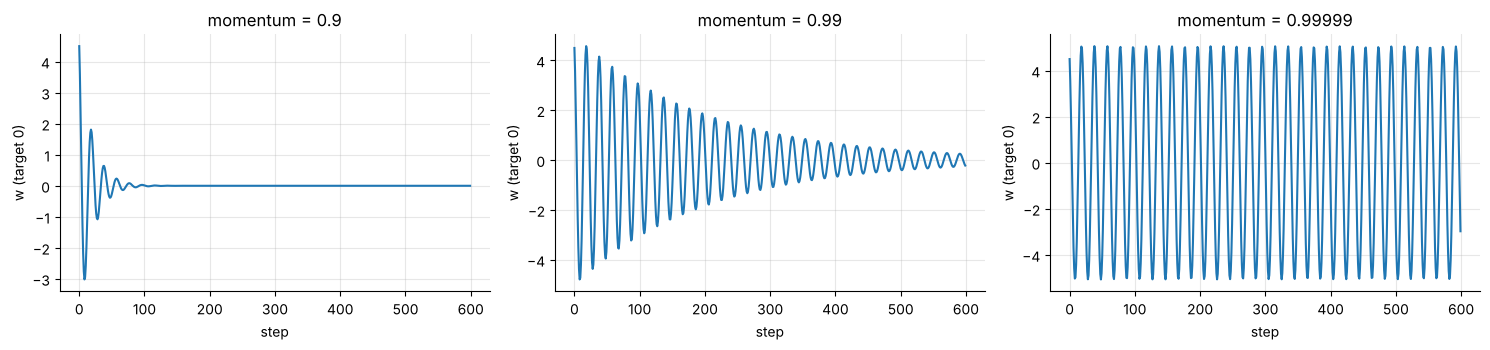

,momentum,steps until |w| < 0.001 (after which it stays),largest |w| after step 100,|w| at step 5000
0,0.90000,158,0.02,1.95e-114
1,0.99000,1688,2.93,3.26e-11
2,0.99999,never within 5000 steps,5.06,0.543


In [5]:
def momentum_run(beta, lr=0.1, steps=5000, w0=5.0):
    w, v, hist = w0, 0.0, []
    for _ in range(steps):
        grad = w                                    # loss = w^2 / 2, minimum at 0
        v = beta * v - lr * grad; w = w + v; hist.append(w)
    return np.array(hist)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6)); rows = []
for ax, beta in zip(axes, (0.9, 0.99, 0.99999)):
    h = momentum_run(beta); ax.plot(h[:600]); ax.set_title(f"momentum = {beta}"); ax.set_xlabel("step"); ax.set_ylabel("w (target 0)")
    settled = np.where(np.abs(h) < 1e-3)[0]
    rows.append({"momentum": beta, "steps until |w| < 0.001 (after which it stays)": int(np.where(np.abs(h) >= 1e-3)[0].max() + 1) if np.abs(h[-1]) < 1e-3 else "never within 5000 steps",
                 "largest |w| after step 100": round(float(np.abs(h[100:]).max()), 2), "|w| at step 5000": f"{abs(h[-1]):.3g}"})
plt.tight_layout(); plt.show(); display(pd.DataFrame(rows))

### Task 1.5 — Review question 6: *Name three ways to produce a sparse model.*

1. **Train normally, then zero out the tiny weights** (magnitude pruning).
2. **ℓ1 regularization** during training (pushes many weights to exactly ≈ 0).
3. The **TensorFlow Model Optimization Toolkit** (pruning during training, with a schedule that gradually removes the weakest weights; the result can also be stored compressed).

(Dual-averaging / FTRL with ℓ1 is another classic route.) Below: ℓ1 versus ordinary training, then pruning the tiny weights after training.

In [6]:
X_s, y_s = X_train[:15000], y_train[:15000]
def sparse_demo(l1=None):
    reg = keras.regularizers.l1(l1) if l1 else None
    net = keras.Sequential([layers.Input((28, 28)), layers.Flatten(),
                            layers.Dense(100, activation="elu", kernel_initializer="he_normal", kernel_regularizer=reg), layers.Dense(10, activation="softmax")])
    net.compile(loss="sparse_categorical_crossentropy", optimizer=keras.optimizers.Nadam(learning_rate=0.002), metrics=["accuracy"])
    reset_seed(); net.fit(X_s, y_s, epochs=ep(8), batch_size=128, verbose=0); return net
rows = []
for name, l1 in [("plain training", None), ("l1 regularization (1e-4)", 1e-4)]:
    net = sparse_demo(l1); acc = net.evaluate(X_valid, y_valid, verbose=0)[1]
    K = net.layers[1].get_weights()
    rows.append({"model": name, "validation accuracy": round(acc, 4), "share of first-layer weights |w| < 0.001": f"{np.mean(np.abs(K[0]) < 1e-3):.1%}"})
    # way 1: prune the tiny weights after training
    K_pruned = [np.where(np.abs(K[0]) < 0.01, 0.0, K[0]), K[1]]; net.layers[1].set_weights(K_pruned)
    rows.append({"model": name + " + prune |w| < 0.01", "validation accuracy": round(net.evaluate(X_valid, y_valid, verbose=0)[1], 4),
                 "share of first-layer weights |w| < 0.001": f"{np.mean(np.abs(K_pruned[0]) < 1e-3):.1%}"})
display(pd.DataFrame(rows))
a_plain, a_plain_p, a_l1, a_l1_p = [r_["validation accuracy"] for r_ in rows]
print(f"pruning |w| < 0.01 changed the accuracy by {100 * (a_plain_p - a_plain):+.2f} points (plain model) and {100 * (a_l1_p - a_l1):+.2f} points (l1 model); "
      f"training with l1 instead of plainly changed it by {100 * (a_l1 - a_plain):+.2f} points")

,model,validation accuracy,share of first-layer weights |w| < 0.001
0,plain training,0.8590,1.1%
1,plain training + prune |w| < 0.01,0.8596,10.7%
2,l1 regularization (1e-4),0.8540,25.8%
3,l1 regularization (1e-4) + prune |w| < 0.01,0.8588,64.8%


pruning |w| < 0.01 changed the accuracy by +0.06 points (plain model) and +0.48 points (l1 model); training with l1 instead of plainly changed it by -0.50 points


Read the last column: the ℓ1-trained model has many more weights close to zero than the plainly trained one, and pruning (setting weights with |w| < 0.01 to exactly 0) removes more of them from the ℓ1 model, because ℓ1 has already pushed many weights towards 0. The line printed under the table says what each step cost in accuracy (a few hundredths of a point is just run-to-run noise). (A sparse model is smaller once stored in a sparse format and can run faster on suitable hardware.)

### Task 1.5 — Review question 7: *Does dropout slow down training? Inference? What about MC Dropout?*

* **Training: yes, usually.** Each step trains a randomly thinned network, so the model typically needs **more epochs** to converge (about 2× is a common rule of thumb); the cost per step is almost the same.
* **Inference: no.** At prediction time dropout is switched off and the layer is a no-op, so a dropout model predicts as fast as the same model without it.
* **MC Dropout: yes at inference.** It predicts `N` times with dropout on (e.g. N = 50–100), so inference is about **N× slower** (training is unaffected).

In [7]:
def drop_net(rate):
    layers_ = [layers.Input((28, 28)), layers.Flatten()]
    for n in (300, 100):
        layers_.append(layers.Dense(n, activation="elu", kernel_initializer="he_normal"))
        if rate: layers_.append(layers.Dropout(rate))
    return keras.Sequential(layers_ + [layers.Dense(10, activation="softmax")])
rows, nets = [], {}
for name, rate in [("no dropout", 0.0), ("dropout 0.3", 0.3)]:
    reset_seed(); net = drop_net(rate); net.compile(loss="sparse_categorical_crossentropy", optimizer=keras.optimizers.Nadam(learning_rate=0.002), metrics=["accuracy"])
    t0 = time.time(); h = net.fit(X_train, y_train, epochs=ep(5), batch_size=128, validation_data=(X_valid, y_valid), verbose=0); t_train = (time.time() - t0) / ep(5)
    t0 = time.time(); net.predict(X_valid, verbose=0, batch_size=5000); t_inf = time.time() - t0
    nets[name] = net
    rows.append({"model": name, f"val accuracy after {ep(5)} epochs": round(h.history["val_accuracy"][-1], 4), "train accuracy": round(h.history["accuracy"][-1], 4),
                 "seconds per training epoch": round(t_train, 1), "inference time, 5000 images (s)": round(t_inf, 3)})
net = nets["dropout 0.3"]
t0 = time.time(); _ = np.stack([net(X_valid, training=True).numpy() for _ in range(50)]).mean(0); t_mc = time.time() - t0
rows.append({"model": "dropout 0.3 + MC Dropout (N = 50)", "inference time, 5000 images (s)": round(t_mc, 3)})
display(pd.DataFrame(rows).fillna("-"))
print(f"MC Dropout (N = 50) took {t_mc / rows[1]['inference time, 5000 images (s)']:.0f}x the time of one plain prediction pass of the same model (50 passes in theory)")

,model,val accuracy after 5 epochs,train accuracy,seconds per training epoch,"inference time, 5000 images (s)"
0,no dropout,0.8722,0.9009,3.8,0.210
1,dropout 0.3,0.862,0.8664,3.3,0.195
2,dropout 0.3 + MC Dropout (N = 50),-,-,-,2.540


MC Dropout (N = 50) took 13x the time of one plain prediction pass of the same model (50 passes in theory)


**Reading the table.** The seconds-per-epoch and the plain inference time are about the same with and without dropout; the dropout model has a lower training accuracy (it is harder to fit) and usually needs more epochs; MC Dropout with N = 50 needs 50 forward passes, so its inference time grows with N; the line under the table gives the measured factor (up to N× in theory — less when the single-pass timing includes fixed overhead).

### Task 1.4 (continued) — Low-latency tricks, shown for real

**Folding Batch Norm into the previous Dense layer.** At inference, Batch Norm is just a fixed linear map, so it can be merged into the layer before it: with `s = γ / √(σ² + ε)`, the new weights are `W' = W·s` and the new bias `b' = (b − μ)·s + β`. The network gets one layer fewer to execute and gives the **same** answers.

In [8]:
reset_seed()
bn_net = keras.Sequential([layers.Input((8,)), layers.Dense(20), layers.BatchNormalization(), layers.Activation("relu"), layers.Dense(1)])
bn_net.compile(loss="mse", optimizer=keras.optimizers.Nadam(learning_rate=0.002)); bn_net.fit(X_train_h, y_train_h, epochs=ep(5), batch_size=64, verbose=0)

dense, bn = bn_net.layers[0], bn_net.layers[1]
W, b = dense.get_weights(); gamma, beta, mean, var = bn.get_weights()
s = gamma / np.sqrt(var + bn.epsilon)
folded = keras.Sequential([layers.Input((8,)), layers.Dense(20), layers.Activation("relu"), layers.Dense(1)])
folded.layers[0].set_weights([W * s, (b - mean) * s + beta]); folded.layers[2].set_weights(bn_net.layers[3].get_weights())
p1, p2 = bn_net.predict(X_test_h, verbose=0), folded.predict(X_test_h, verbose=0)
print(f"layers before folding: {len(bn_net.layers)}, after: {len(folded.layers)}   |   largest difference between the two models' predictions: {np.abs(p1 - p2).max():.2e}")

# lower float precision: 32 -> 16 and 8 bits (weights only, simulated)
def quantize(net_weights, kind):
    out = []
    for w in net_weights:
        if kind == "float16": out.append(w.astype("float16").astype("float32"))
        else:                                                      # symmetric 8-bit integers: w ~ q * scale
            scale = np.abs(w).max() / 127 + 1e-12; out.append((np.round(w / scale).clip(-127, 127) * scale).astype("float32"))
    return out
rows = []
for kind, bytes_per in [("float32 (original)", 4), ("float16", 2), ("int8", 1)]:
    q = keras.models.clone_model(folded); q.set_weights(folded.get_weights() if kind.startswith("float32") else quantize(folded.get_weights(), kind.split()[0]))
    pq = q.predict(X_test_h, verbose=0); n_params = sum(w.size for w in folded.get_weights())
    rows.append({"precision": kind, "model size (bytes)": n_params * bytes_per, "largest prediction change": f"{np.abs(pq - p2).max():.1e}", "test MAE": round(float(np.mean(np.abs(pq.ravel() - y_test_h.ravel()))), 4)})
display(pd.DataFrame(rows))

layers before folding: 4, after: 3   |   largest difference between the two models' predictions: 1.43e-06


,precision,model size (bytes),largest prediction change,test MAE
0,float32 (original),804,0.0e+00,0.4525
1,float16,402,2.6e-03,0.4525
2,int8,201,2.4e-01,0.4547


The folded model is mathematically identical (differences are floating-point round-off), and halving or quartering the precision cuts the size by 2× or 4× while barely changing the error.

### Task 1.6 — The design decision tree

```
Start: a deep network problem
│
├─ Can the default recipe (He+ELU, BN if deep, early stopping, Nadam/momentum, 1cycle) + model.fit() do it?  ──► YES: use Keras only (≈ 95 % of real projects)
│
├─ Is it a plain Dense stack that should normalize itself?  ───────────────────────────────► SNN recipe (LeCun + SELU, standardized inputs, alpha dropout)
│
├─ Exception: sparse model ───────► ℓ1 / pruning (TF Model Optimization Toolkit), default config
├─ Exception: low latency  ───────► fewer layers, fold BN, ReLU/leaky ReLU, sparse, 16/8-bit
├─ Exception: risk-sensitive ─────► MC Dropout
│
└─ Does the project need something Keras does not give out of the box?  ──► go LOW-LEVEL (the rest of this task):
      ★ "I need a custom loss"                      → Phase 3 (custom loss function / Loss subclass)
      ★ "I need a custom training algorithm"        → Phase 7 (custom training loop)
      ★ "I need to tweak gradients beyond clipping" → Phase 6 + 7 (GradientTape, transform gradients before apply_gradients)
      ★ "I need multiple optimizers"                → Phase 7 + 8 (custom loop with one optimizer per group of variables)
```

These four ★ cases are exactly the ones that need the lower-level API in the rest of this task.

### ✅ Phase 1 deliverable
Both configuration tables ✔ · three-exceptions summary ✔ · answers to the seven review questions (with small experiments) ✔ · design decision tree ✔

---
# Phase 2 — A Quick Tour of TensorFlow & Using It Like NumPy

**Simple idea.** TensorFlow is "**NumPy that runs on a GPU and can differentiate itself**". You write maths on arrays; TensorFlow can run it on faster hardware, work out gradients automatically, and even compile your Python function into an optimized graph.

**Real-life example.** NumPy is a skilled cook working in a home kitchen. TensorFlow is the same recipe, but in a restaurant kitchen with many stoves (GPUs/TPUs), a head chef who plans the order of work (the graph compiler), and a recipe book that can be shipped to other restaurants (graph export).

### Task 2.1 — What TensorFlow offers

* A **NumPy-like core with GPU support**.
* **Distributed computing** across many devices/machines.
* A **JIT-style compiler** that extracts a *computation graph* from your Python function and optimizes it (prunes unused parts, simplifies expressions, runs independent operations in parallel).
* **Portable graph export:** train in Python, then run the graph from C++, a phone, a browser, a server…
* **Autodiff** (automatic differentiation) plus good built-in optimizers (RMSProp, Nadam…).

### Task 2.2 — The ecosystem

| Piece | What it is for |
|---|---|
| `tf.keras` | The high-level model API |
| `tf.data` | Efficient input pipelines |
| `tf.io` | Reading/writing files and records |
| `tf.image` | Image operations (resize, crop, flip…) |
| `tf.signal` | FFT and signal processing |
| TensorBoard | Training visualization |
| TFX | Production ML pipelines |
| TF Serving | Serving models over the network |
| TensorFlow Hub | Downloadable pretrained model components |
| Model Garden | Reference implementations of popular models |
| TensorFlow Lite | Phones and embedded devices |
| TensorFlow.js | Models in the browser / Node.js |

### Task 2.3 — Ops and kernels

Every TensorFlow **operation (op)** — `tf.add`, `tf.matmul`, `tf.nn.relu`… — has a fast **C++ implementation**, and for each type of device it has a separate **kernel** (a CPU kernel, a GPU kernel, a TPU kernel). When you run an op, TensorFlow picks the kernel that matches the device where the data lives.

### Task 2.4 — Creating tensors, shapes, dtypes and indexing

In [9]:
t = tf.constant([[1., 2., 3.], [4., 5., 6.]])               # a matrix
print(t, "\n")
print("shape :", t.shape, "| dtype:", t.dtype)
scalar = tf.constant(42)                                     # a scalar
print("scalar:", scalar.numpy(), "| shape:", scalar.shape, "| dtype:", scalar.dtype)

print("\nt[:, 1:]            ->\n", t[:, 1:].numpy())
print("t[..., 1, tf.newaxis] ->\n", t[..., 1, tf.newaxis].numpy(), "   (column 1 of every row, as a column vector)")

tf.Tensor(
[[1. 2. 3.]
 [4. 5. 6.]], shape=(2, 3), dtype=float32) 

shape : (2, 3) | dtype: <dtype: 'float32'>
scalar: 42 | shape: () | dtype: <dtype: 'int32'>

t[:, 1:]            ->
 [[2. 3.]
 [5. 6.]]
t[..., 1, tf.newaxis] ->
 [[2.]
 [5.]]    (column 1 of every row, as a column vector)


### Task 2.5 — Operations (`+`, `tf.square`, `@`)

In [10]:
print("t + 10            ->", (t + 10).numpy().tolist())
print("tf.add(t, 10)     ->", tf.add(t, 10).numpy().tolist(), "   (the same thing)")
print("tf.square(t)      ->", tf.square(t).numpy().tolist())
print("t @ tf.transpose(t) ->", (t @ tf.transpose(t)).numpy().tolist())
print("tf.matmul(...) same ->", np.allclose((t @ tf.transpose(t)).numpy(), tf.matmul(t, tf.transpose(t)).numpy()), "(@ is tf.matmul)")

t + 10            -> [[11.0, 12.0, 13.0], [14.0, 15.0, 16.0]]
tf.add(t, 10)     -> [[11.0, 12.0, 13.0], [14.0, 15.0, 16.0]]    (the same thing)
tf.square(t)      -> [[1.0, 4.0, 9.0], [16.0, 25.0, 36.0]]
t @ tf.transpose(t) -> [[14.0, 32.0], [32.0, 77.0]]
tf.matmul(...) same -> True (@ is tf.matmul)


### Task 2.6 — Differences in names and behaviour from NumPy

| NumPy | TensorFlow | Note |
|---|---|---|
| `np.mean`, `np.sum`, `np.max` | `tf.reduce_mean`, `tf.reduce_sum`, `tf.reduce_max` | "reduce" because they reduce a dimension; some are implemented with a different, GPU-friendly kernel |
| `np.log` | `tf.math.log` | `tf.log` was removed; many math ops live in `tf.math` |
| `a.T` (a *view*, no copy) | `tf.transpose(t)` (a **copy**) | a TF tensor is immutable, and a transposed *view* is not supported |
| dtype `float64` by default | dtype `float32` by default | 32 bits are faster and use half the memory; enough precision for neural nets |

**Why `reduce_sum` can differ between runs on a GPU.** Floating-point addition is *not associative* (`(a+b)+c ≠ a+(b+c)` in the last digits). A GPU adds thousands of numbers in parallel and the order in which the partial sums arrive is not guaranteed, so two runs may differ in the last digits of a 32-bit float. We can imitate this on the CPU just by adding the same numbers in a different order:

In [11]:
a = np.arange(6).reshape(2, 3)
print("NumPy a.T shares memory with a (a view):", np.shares_memory(a, a.T))

x = np.random.default_rng(0).normal(size=1_000_000).astype("float32")
orders = [x, x[::-1].copy(), np.random.default_rng(1).permutation(x)]
sums = [float(np.cumsum(o, dtype=np.float32)[-1]) for o in orders]            # plain one-by-one float32 additions
print("the same 1,000,000 float32 numbers added in 3 different orders:")
for s_ in sums: print(f"   {s_:.6f}")
print("exact sum computed in float64:", f"{x.astype('float64').sum():.6f}")

NumPy a.T shares memory with a (a view): True
the same 1,000,000 float32 numbers added in 3 different orders:
   998.564270
   998.541443
   998.576904
exact sum computed in float64: 998.570663


### Task 2.7 — Converting between NumPy and TensorFlow

In [12]:
a = np.array([2., 4., 5.])
print("np array dtype                  :", a.dtype)
print("tf.constant(a).dtype            :", tf.constant(a).dtype, "  <- keeps NumPy's 64 bits")
print("tf.constant(a, dtype=tf.float32):", tf.constant(a, dtype=tf.float32).dtype, "  <- what we normally want")
print("t.numpy()                       ->\n", t.numpy())
print("np.array(t) is the same         :", np.array_equal(np.array(t), t.numpy()))
print("np.square(t)  (NumPy function on a tensor) ->", np.square(t).tolist(), "-> type:", type(np.square(t)).__name__)
print("tf.square(a)  (TF function on an array)    ->", tf.square(a).numpy().tolist(), "-> dtype:", tf.square(a).dtype)

np array dtype                  : float64
tf.constant(a).dtype            : <dtype: 'float64'>   <- keeps NumPy's 64 bits
tf.constant(a, dtype=tf.float32): <dtype: 'float32'>   <- what we normally want
t.numpy()                       ->
 [[1. 2. 3.]
 [4. 5. 6.]]
np.array(t) is the same         : True
np.square(t)  (NumPy function on a tensor) -> [[1.0, 4.0, 9.0], [16.0, 25.0, 36.0]] -> type: ndarray
tf.square(a)  (TF function on an array)    -> [4.0, 16.0, 25.0] -> dtype: <dtype: 'float64'>


### Task 2.8 — No automatic type conversion — use `tf.cast`

TensorFlow refuses to add a `float32` to an `int32`. Hidden conversions would silently cost speed and memory (every conversion copies data), so TF makes you ask for them explicitly.

In [13]:
def show_error(fn):
    try: print(fn())
    except Exception as ex: print(f"{type(ex).__name__}: {str(ex).splitlines()[0][:150]}")

show_error(lambda: tf.constant(2.) + tf.constant(40))
show_error(lambda: tf.constant(2.) + tf.constant(40., dtype=tf.float64))
print("with tf.cast ->", (tf.constant(2.) + tf.cast(tf.constant(40), tf.float32)).numpy())

InvalidArgumentError: cannot compute AddV2 as input #1(zero-based) was expected to be a float tensor but is a int32 tensor [Op:AddV2] name: 
InvalidArgumentError: cannot compute AddV2 as input #1(zero-based) was expected to be a float tensor but is a double tensor [Op:AddV2] name: 
with tf.cast -> 42.0


### Task 2.9 — `tf.Variable`: the mutable tensor

A `tf.Tensor` is **immutable** — you can compute new tensors from it but not change it. A neural network's weights must change at every training step, so TensorFlow gives us `tf.Variable`, a tensor you can modify **in place** with `assign()`, `assign_add()`, slice assignment and `scatter_nd_update()`. (You will rarely create variables by hand: Keras layers do it for you through `add_weight()`.)

In [14]:
v = tf.Variable([[1., 2., 3.], [4., 5., 6.]])
print("start             :", v.numpy().tolist())
v.assign(2 * v);                                  print("v.assign(2 * v)   :", v.numpy().tolist())
v[0, 1].assign(42.);                              print("v[0, 1].assign(42):", v.numpy().tolist())
v[:, 2].assign([0., 1.]);                         print("v[:, 2].assign([0,1]):", v.numpy().tolist())
v.assign_add(tf.ones_like(v));                    print("v.assign_add(ones):", v.numpy().tolist())
v.scatter_nd_update(indices=[[0, 0], [1, 2]], updates=[100., 200.]); print("scatter_nd_update :", v.numpy().tolist())
def item_assignment():
    v[1] = 3.                                            # the NumPy way -- not allowed on a TF variable
show_error(item_assignment)

start             : [[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]]
v.assign(2 * v)   : [[2.0, 4.0, 6.0], [8.0, 10.0, 12.0]]
v[0, 1].assign(42): [[2.0, 42.0, 6.0], [8.0, 10.0, 12.0]]
v[:, 2].assign([0,1]): [[2.0, 42.0, 0.0], [8.0, 10.0, 1.0]]
v.assign_add(ones): [[3.0, 43.0, 1.0], [9.0, 11.0, 2.0]]
scatter_nd_update : [[100.0, 43.0, 1.0], [9.0, 11.0, 200.0]]
TypeError: 'ResourceVariable' object does not support item assignment


### Task 2.10 — The six other data structures

| Structure | One-line use case |
|---|---|
| **Sparse tensors** (`tf.SparseTensor`) | Efficiently store tensors that are mostly zeros (e.g. a bag-of-words matrix with 50,000 columns of which 20 are non-zero). |
| **Tensor arrays** (`tf.TensorArray`) | A list of tensors of the same shape, with a fixed or dynamic size; the right tool for building results step by step inside a graph loop. |
| **Ragged tensors** (`tf.RaggedTensor`) | A list of lists with different lengths (sentences of different word counts) without padding. |
| **String tensors** (`tf.string`) | Text as *byte strings*; use `tf.strings` to measure/join/split, or `unicode_decode` for Unicode code points (the length of "café" is 5 bytes but 4 characters). |
| **Sets** (`tf.sets`) | Sets as ordinary (sparse) tensors with `union`, `intersection`, `difference`. |
| **Queues** (`tf.queue`) | Storing tensors across several steps: FIFO, priority, random shuffle and padding FIFO queues. |

In [15]:
# sparse tensor
s = tf.SparseTensor(indices=[[0, 1], [1, 0], [2, 3]], values=[1., 2., 3.], dense_shape=[3, 4])
print("sparse -> dense:\n", tf.sparse.to_dense(s).numpy())
print("sparse x dense matrix:\n", tf.sparse.sparse_dense_matmul(s, tf.ones([4, 2])).numpy())

# tensor array
ta = tf.TensorArray(tf.float32, size=3).write(0, 1.).write(1, 2.).write(2, 3.)
print("\ntensor array stacked:", ta.stack().numpy())

# ragged tensor
r = tf.ragged.constant([[1, 2], [3], [4, 5, 6]])
print("\nragged:", r, "| row sums:", tf.reduce_sum(r, axis=1).numpy(), "| padded:\n", r.to_tensor().numpy())

# string tensors
st = tf.constant("café")
print("\nstring: bytes =", tf.strings.length(st).numpy(), "| characters =", tf.strings.length(st, unit="UTF8_CHAR").numpy(),
      "| code points =", tf.strings.unicode_decode(st, "UTF-8").numpy())

# sets
A, B = tf.constant([[1, 5, 9]]), tf.constant([[5, 6, 9, 11]])
print("\nsets: union", tf.sparse.to_dense(tf.sets.union(A, B)).numpy(), "| intersection", tf.sparse.to_dense(tf.sets.intersection(A, B)).numpy(),
      "| difference", tf.sparse.to_dense(tf.sets.difference(A, B)).numpy())

# queues
fifo = tf.queue.FIFOQueue(3, [tf.int32]); fifo.enqueue([10]); fifo.enqueue([20])
prio = tf.queue.PriorityQueue(3, [tf.string], shapes=[()]); prio.enqueue([tf.constant(2, tf.int64), "low priority"]); prio.enqueue([tf.constant(1, tf.int64), "high priority"])
pad = tf.queue.PaddingFIFOQueue(3, [tf.int32], shapes=[(None,)]); pad.enqueue([[1, 2]]); pad.enqueue([[3]])
print("\nFIFO queue first out:", fifo.dequeue().numpy(), "| priority queue first out:", prio.dequeue()[1].numpy(), "| padding FIFO (2 items):", pad.dequeue_many(2).numpy().tolist())

sparse -> dense:
 [[0. 1. 0. 0.]
 [2. 0. 0. 0.]
 [0. 0. 0. 3.]]
sparse x dense matrix:
 [[1. 1.]
 [2. 2.]
 [3. 3.]]

tensor array stacked: [1. 2. 3.]

ragged: <tf.RaggedTensor [[1, 2], [3], [4, 5, 6]]> | row sums: [ 3  3 15] | padded:
 [[1 2 0]
 [3 0 0]
 [4 5 6]]

string: bytes = 5 | characters = 4 | code points = [ 99  97 102 233]

sets: union [[ 1  5  6  9 11]] | intersection [[5 9]] | difference [[1]]

FIFO queue first out: 10 | priority queue first out: b'high priority' | padding FIFO (2 items): [[1, 2], [3, 0]]


### ✅ Phase 2 deliverable
Tasks 2.4–2.9 demonstrated with printed outputs ✔ · six extra data structures described and demonstrated ✔

---
# Phase 3 — Custom Loss Functions & Saving Custom Components

**Simple idea.** The *loss* is the score the network tries to push down. Keras ships the usual ones, but real data is messy. If a few house prices in your data are typos (an extra zero), plain MSE gives those few typos a huge say in training. A **custom loss** lets you decide how much each mistake should hurt.

**Real-life example.** A teacher marking an exam: for small slips she subtracts a little (the penalty grows like the *square* of the error — fair for small mistakes); for a wildly wrong answer she does not want one question to ruin the whole grade, so beyond a point the penalty grows only *in a straight line*. That is the **Huber loss**.

### Task 3.1 — Why Huber loss for noisy regression data

* **MSE** (squared error) over-penalizes large errors: a few outliers dominate and the model chases them.
* **MAE** (absolute error) is robust, but its gradient has constant size, so training does not settle precisely near the minimum and converges slowly.
* **Huber** is **quadratic for small errors** (smooth, precise convergence) and **linear for large errors** (robust to outliers).

### Task 3.2 — Huber as a function using only TensorFlow operations

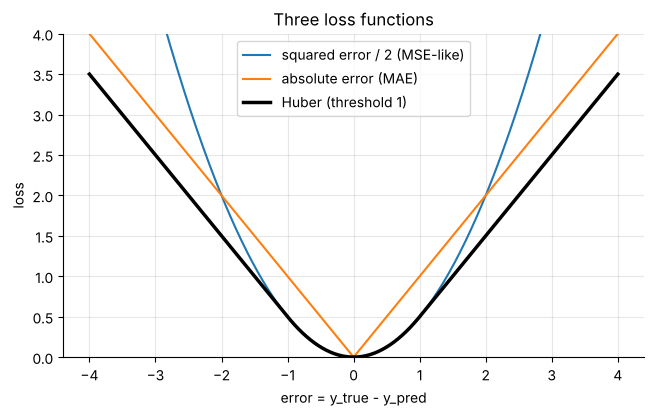

per-instance Huber losses:

 [0.04499999 0.         5.5       ]   <- one loss value per instance, computed for the whole batch at once
same as keras.losses.Huber() averaged: True


In [16]:
def huber_fn(y_true, y_pred):
    error = y_true - y_pred
    is_small_error = tf.abs(error) < 1
    squared_loss = tf.square(error) / 2
    linear_loss = tf.abs(error) - 0.5
    return tf.where(is_small_error, squared_loss, linear_loss)

# a picture of the three losses
e = np.linspace(-4, 4, 400).astype("float32")
plt.figure(figsize=(7.5, 4.2))
plt.plot(e, e ** 2 / 2, label="squared error / 2 (MSE-like)"); plt.plot(e, np.abs(e), label="absolute error (MAE)"); plt.plot(e, huber_fn(e, 0.0).numpy(), "k", lw=2.5, label="Huber (threshold 1)")
plt.ylim(0, 4); plt.xlabel("error = y_true - y_pred"); plt.ylabel("loss"); plt.legend(); plt.title("Three loss functions"); plt.show()

yt, yp = tf.constant([[1.0], [2.0], [10.0]]), tf.constant([[1.3], [2.0], [4.0]])
print("per-instance Huber losses:", huber_fn(yt, yp).numpy().ravel(), "  <- one loss value per instance, computed for the whole batch at once")
print("same as keras.losses.Huber() averaged:", np.isclose(huber_fn(yt, yp).numpy().mean(), keras.losses.Huber()(yt, yp).numpy()))

**Why vectorized and one loss per instance?** (1) *Vectorized* (no Python loop over the batch): the whole batch is computed in a few fast tensor operations — a Python loop would be hundreds of times slower and could not run inside a graph. (2) *One loss per instance* (not a single averaged number): Keras can then apply **sample weights** and **class weights** to each instance before it averages the losses itself.

### Task 3.3 — Train on California Housing with `huber_fn`, `keras.losses.Huber()` and MSE

In [17]:
def train_housing(loss, y=None, epochs=20, seed=SEED, metrics=("mae",)):
    reset_seed(seed); net = housing_mlp(loss=loss, metrics=list(metrics))
    h = net.fit(X_train_h, y_train_h if y is None else y, epochs=ep(epochs), batch_size=64, validation_data=(X_valid_h, y_valid_h), verbose=0)
    return net, h

compare = {}
for name, loss in [("MSE", "mse"), ("huber_fn (our function)", huber_fn), ("keras.losses.Huber()", keras.losses.Huber())]:
    net, h = train_housing(loss); compare[name] = net
    mae, mse = mae_mse(net); print(f"{name:26s} test MAE = {mae:.4f} | test MSE = {mse:.4f}")

MSE                        test MAE = 0.3928 | test MSE = 0.3245


huber_fn (our function)    test MAE = 0.3837 | test MSE = 0.3216


keras.losses.Huber()       test MAE = 0.3837 | test MSE = 0.3216


Our own `huber_fn` and Keras's `Huber()` are the same formula, so their results are (nearly) identical; the difference from MSE is small on this fairly clean data. Where Huber really pays off is **noisy labels**, so let us corrupt 5 % of the training targets with big random errors (like data-entry typos), train with MSE, MAE and Huber, and evaluate on the *clean* test set:

In [18]:
rng = np.random.default_rng(7)
y_noisy = y_train_h.copy(); bad = rng.choice(len(y_noisy), size=int(0.05 * len(y_noisy)), replace=False)
y_noisy[bad] += rng.choice([-1, 1], size=(len(bad), 1)) * rng.uniform(3, 8, size=(len(bad), 1)).astype("float32")
print(f"{len(bad)} of {len(y_noisy)} training targets corrupted (+/- 3 to 8 units = $300k-$800k)")
rows = []
for name, loss in [("MSE", "mse"), ("MAE", "mae"), ("Huber (threshold 1)", keras.losses.Huber(delta=1.0))]:
    net, _ = train_housing(loss, y=y_noisy); mae, mse = mae_mse(net)
    rows.append({"loss used for training (noisy labels)": name, "clean test MAE": round(mae, 4), "clean test MSE": round(mse, 4)})
tbl = pd.DataFrame(rows); display(tbl)
best = tbl.loc[tbl["clean test MAE"].idxmin(), "loss used for training (noisy labels)"]
print(f"-> lowest clean-test MAE with noisy labels: {best}")
t_mse, t_mae, t_hub = [tbl.loc[i, "clean test MAE"] for i in range(3)]
print(f"Huber vs MSE: clean test MAE {100 * (1 - t_hub / t_mse):.0f}% lower | Huber vs MAE: {100 * (t_hub / t_mae - 1):+.0f}%")
if t_mae < t_hub: print("MAE is itself the score used here, so training with MAE has a small home advantage; Huber is the compromise: smooth like MSE near 0, robust like MAE for large errors.")

619 of 12384 training targets corrupted (+/- 3 to 8 units = $300k-$800k)


,loss used for training (noisy labels),clean test MAE,clean test MSE
0,MSE,0.4391,0.3792
1,MAE,0.3891,0.3322
2,Huber (threshold 1),0.3949,0.3256


-> lowest clean-test MAE with noisy labels: MAE
Huber vs MSE: clean test MAE 10% lower | Huber vs MAE: +1%
MAE is itself the score used here, so training with MAE has a small home advantage; Huber is the compromise: smooth like MSE near 0, robust like MAE for large errors.


### Task 3.4 — Save the model and load it back with `custom_objects`

Keras saves the model's architecture and weights, and for a custom loss it saves only the **name** (`"huber_fn"`) — not the Python code. When loading, you must tell Keras what that name means with `custom_objects={"huber_fn": huber_fn}`.

In [19]:
os.makedirs("saved_models", exist_ok=True)
net_fn, _ = train_housing(huber_fn, epochs=10)
net_fn.save("saved_models/huber_function.keras")

try:
    keras.models.load_model("saved_models/huber_function.keras")
    print("loaded without custom_objects (unexpected)")
except Exception as ex:
    print("Without custom_objects ->", type(ex).__name__, ":", str(ex).splitlines()[0][:170])

loaded_fn = keras.models.load_model("saved_models/huber_function.keras", custom_objects={"huber_fn": huber_fn})
print("With custom_objects={'huber_fn': huber_fn} -> loaded; predictions identical:", np.allclose(net_fn.predict(X_test_h[:50], verbose=0), loaded_fn.predict(X_test_h[:50], verbose=0), atol=1e-5))

Without custom_objects -> TypeError : Could not locate function 'huber_fn'. Make sure custom classes and functions are decorated with `@keras.saving.register_keras_serializable()`. If they are already decorat


With custom_objects={'huber_fn': huber_fn} -> loaded; predictions identical: True


### Task 3.5 — A configurable version with a closure: `create_huber(threshold)`

A function cannot carry a setting like "threshold = 2", so we build a function *factory*: `create_huber(2.0)` returns a Huber function that remembers its threshold (a *closure*).

In [20]:
def create_huber(threshold=1.0):
    def huber_fn(y_true, y_pred):
        error = y_true - y_pred
        is_small_error = tf.abs(error) < threshold
        squared_loss = tf.square(error) / 2
        linear_loss = threshold * tf.abs(error) - threshold ** 2 / 2
        return tf.where(is_small_error, squared_loss, linear_loss)
    return huber_fn

net_cl, _ = train_housing(create_huber(2.0), epochs=10)
net_cl.save("saved_models/huber_closure.keras")

# the file only knows the NAME "huber_fn" -> the threshold is whatever function we hand over at load time
ok = keras.models.load_model("saved_models/huber_closure.keras", custom_objects={"huber_fn": create_huber(2.0)})
wrong = keras.models.load_model("saved_models/huber_closure.keras", custom_objects={"huber_fn": create_huber(1.0)})   # no error!
loss_ok = ok.evaluate(X_test_h, y_test_h, verbose=0); loss_wrong = wrong.evaluate(X_test_h, y_test_h, verbose=0)
print(f"loaded with threshold 2.0 -> test loss {loss_ok[0] if isinstance(loss_ok, list) else loss_ok:.4f}")
print(f"loaded with threshold 1.0 -> test loss {loss_wrong[0] if isinstance(loss_wrong, list) else loss_wrong:.4f}   <- silently a different loss: the threshold was NOT saved")

loaded with threshold 2.0 -> test loss 0.1722
loaded with threshold 1.0 -> test loss 0.1537   <- silently a different loss: the threshold was NOT saved


**Result:** the threshold is **not** saved with the model. If you load it with a different threshold, Keras does not complain — you just get a different loss — so you *must* pass `custom_objects={"huber_fn": create_huber(2.0)}` yourself and remember which threshold you trained with.

### Task 3.6 — The fix: subclass `keras.losses.Loss`

In [21]:
class HuberLoss(keras.losses.Loss):
    def __init__(self, threshold=1.0, **kwargs):
        self.threshold = threshold
        super().__init__(**kwargs)
    def call(self, y_true, y_pred):
        error = y_true - y_pred
        is_small_error = tf.abs(error) < self.threshold
        squared_loss = tf.square(error) / 2
        linear_loss = self.threshold * tf.abs(error) - self.threshold ** 2 / 2
        return tf.where(is_small_error, squared_loss, linear_loss)
    def get_config(self):
        base_config = super().get_config()
        return {**base_config, "threshold": self.threshold}

print("get_config():", HuberLoss(2.0).get_config())

get_config(): {'name': 'huber_loss', 'reduction': 'sum_over_batch_size', 'threshold': 2.0}


**What each part does.** `__init__` stores the threshold and passes `**kwargs` (e.g. `name`, `reduction`) to the parent; `call()` computes one loss per instance; `get_config()` returns the base configuration **plus** `threshold`, so Keras can save every hyperparameter.

**The `reduction` argument** says how Keras turns the per-instance losses into one number:

| `reduction` | Result |
|---|---|
| `"sum_over_batch_size"` (default) | sum of the (weighted) losses **÷ batch size** |
| `"sum"` | the plain sum |
| `"none"` | the per-instance losses unchanged |

Why divide by the batch size and not by the sum of the sample weights? Dividing by the sum of weights would *cancel* the weights (doubling every weight would change nothing), so a weight of 0.5 on an instance would not really make it count half as much as the others. Dividing by the batch size keeps the effect of the weights.

In [22]:
yt = tf.constant([[1.0], [2.0], [10.0], [3.0]]); yp = tf.constant([[1.5], [2.0], [4.0], [3.2]]); w = tf.constant([1.0, 1.0, 0.5, 1.0])
for red in ("sum_over_batch_size", "sum", "none"):
    print(f"reduction = {red:20s} ->", np.round(HuberLoss(2.0, reduction=red)(yt, yp, sample_weight=w).numpy(), 4))

reduction = sum_over_batch_size  -> 1.2862
reduction = sum                  -> 5.145
reduction = none                 -> [[0.125]
 [0.   ]
 [5.   ]
 [0.02 ]]


### Task 3.7 — Save/load again: the threshold now survives

On loading, Keras calls the class's `from_config(config)` (by default `HuberLoss(**config)`), which re-creates the loss with the saved `threshold`.

In [23]:
net_cls, _ = train_housing(HuberLoss(2.0), epochs=10)
net_cls.save("saved_models/huber_class.keras")
loaded_cls = keras.models.load_model("saved_models/huber_class.keras", custom_objects={"HuberLoss": HuberLoss})
print("loaded loss object  :", type(loaded_cls.loss).__name__, "| threshold =", loaded_cls.loss.threshold, "  <- survived the round trip")
print("predictions identical:", np.allclose(net_cls.predict(X_test_h[:50], verbose=0), loaded_cls.predict(X_test_h[:50], verbose=0), atol=1e-5))

summary = pd.DataFrame([
    {"variant": "function  huber_fn", "needs custom_objects?": "yes", "threshold saved?": "n/a (fixed at 1)"},
    {"variant": "closure  create_huber(t)", "needs custom_objects?": "yes - and you must rebuild it with the same t", "threshold saved?": "NO"},
    {"variant": "subclass  HuberLoss(t)", "needs custom_objects?": "yes (just the class)", "threshold saved?": "YES, through get_config()"}])
display(summary)

loaded loss object  : HuberLoss | threshold = 2.0   <- survived the round trip


predictions identical: True


,variant,needs custom_objects?,threshold saved?
0,function huber_fn,yes,n/a (fixed at 1)
1,closure create_huber(t),yes - and you must rebuild it with the same t,NO
2,subclass HuberLoss(t),yes (just the class),"YES, through get_config()"


### Task 3.8 — Which components can be subclassed safely?

Keras officially supports subclassing for **layers, models, callbacks and regularizers** — code that uses them is portable across Keras implementations. For **losses, metrics, initializers and constraints**, subclassing works in `tf.keras`, but those classes are not part of the portable Keras specification, so code using them may not run on other Keras implementations. (Plain functions are the portable option for those — at the cost of not saving their hyper-parameters, as we just saw.)

### ✅ Phase 3 deliverable
Three Huber variants (function, closure, subclass) ✔ · save→load round trip for each, showing exactly what is and is not persisted ✔ · test error vs built-in MSE and `keras.losses.Huber` (clean and noisy labels) ✔

---
# Phase 4 — Custom Activations, Initializers, Regularizers, Constraints & Metrics

**Simple idea.** Everything that happens inside a layer is a small replaceable piece: *how the weights start* (initializer), *what shape the output takes* (activation), *what extra penalty is added to the loss* (regularizer) and *what rule the weights must obey after every step* (constraint). If you can write a Python function with TensorFlow operations, you can plug it in.

**Real-life example.** Think of a Lego kit: each piece has a fixed socket shape. As long as your home-made piece has the right shape (inputs/outputs), the model accepts it like the original.

### Task 4.1 — The four function-style components, checked against their built-in twins

In [24]:
def my_softplus(z):                                   # tf.nn.softplus
    return tf.math.log(tf.exp(z) + 1.0)

def my_glorot_initializer(shape, dtype=tf.float32):   # glorot_normal
    stddev = tf.sqrt(2. / (shape[0] + shape[1]))
    return tf.random.normal(shape, stddev=stddev, dtype=dtype)

def my_l1_regularizer(weights):                       # regularizers.l1(0.01)
    return tf.reduce_sum(tf.abs(0.01 * weights))

def my_positive_weights(weights):                     # constraints.nonneg()
    return tf.where(weights < 0., tf.zeros_like(weights), weights)

z = tf.linspace(-5., 5., 101)
W = tf.random.normal([1000, 500], seed=1)
init_ours = my_glorot_initializer((1000, 500)); init_keras = keras.initializers.GlorotNormal(seed=1)((1000, 500))
check = pd.DataFrame([
    {"custom function": "my_softplus", "built-in twin": "tf.nn.softplus", "what we compare": "largest |difference| on 101 points in [-5, 5]",
     "result": f"{float(tf.reduce_max(tf.abs(my_softplus(z) - tf.nn.softplus(z)))):.2e}"},
    {"custom function": "my_glorot_initializer", "built-in twin": "GlorotNormal", "what we compare": "std of a 1000 x 500 weight matrix (theory sqrt(2/1500) = %.4f)" % np.sqrt(2 / 1500),
     "result": f"ours {float(tf.math.reduce_std(init_ours)):.4f} | Keras {float(tf.math.reduce_std(init_keras)):.4f}"},
    {"custom function": "my_l1_regularizer", "built-in twin": "regularizers.l1(0.01)", "what we compare": "penalty of one random weight matrix",
     "result": f"ours {float(my_l1_regularizer(W)):.3f} | Keras {float(keras.regularizers.l1(0.01)(W)):.3f}"},
    {"custom function": "my_positive_weights", "built-in twin": "constraints.NonNeg()", "what we compare": "are the constrained weights identical?",
     "result": str(bool(np.array_equal(my_positive_weights(W).numpy(), keras.constraints.NonNeg()(W).numpy())))}])
pd.set_option("display.max_colwidth", 80); display(check)

,custom function,built-in twin,what we compare,result
0,my_softplus,tf.nn.softplus,"largest |difference| on 101 points in [-5, 5]",2.38e-07
1,my_glorot_initializer,GlorotNormal,std of a 1000 x 500 weight matrix (theory sqrt(2/1500) = 0.0365),ours 0.0365 | Keras 0.0365
2,my_l1_regularizer,regularizers.l1(0.01),penalty of one random weight matrix,ours 3988.262 | Keras 3988.262
3,my_positive_weights,constraints.NonNeg(),are the constrained weights identical?,True


### Task 4.2 — Plug all four into one `Dense` layer — *when is each one called?*

| Component | When Keras calls it |
|---|---|
| **Activation** | On the layer's **output**, every forward pass. |
| **Initializer** | **Once**, when the layer creates its weights. |
| **Regularizer** | **At every training step**: its value is computed from the weights and **added to the loss**. |
| **Constraint** | **After every training step**: the weights are replaced by `constraint(weights)`. |

In [25]:
reset_seed()
custom_dense = layers.Dense(30, activation=my_softplus, kernel_initializer=my_glorot_initializer,
                            kernel_regularizer=my_l1_regularizer, kernel_constraint=my_positive_weights)
net4 = keras.Sequential([layers.Input((8,)), custom_dense, layers.Dense(1)])
net4.compile(loss="mse", optimizer=keras.optimizers.Nadam(learning_rate=0.002))

K0 = custom_dense.kernel.numpy().copy()                                  # weights right after creation (initializer ran)
print(f"initializer : kernel std at creation = {K0.std():.3f}   (formula sqrt(2/(8+30)) = {np.sqrt(2 / 38):.3f}); negative weights at creation: {np.mean(K0 < 0):.0%}")
net4.fit(X_train_h, y_train_h, epochs=ep(5), batch_size=64, verbose=0)
K1 = custom_dense.kernel.numpy()
print(f"constraint  : smallest weight after training = {K1.min():.4f}  (>= 0, so every negative weight was replaced by 0 after each step)")
print(f"regularizer : model.losses = {[round(float(l), 4) for l in net4.losses]} == my_l1_regularizer(kernel) = {float(my_l1_regularizer(custom_dense.kernel)):.4f}   <- added to the loss")
h_act = custom_dense(X_test_h[:5]).numpy()
print(f"activation  : the layer's outputs are all > 0 (softplus): {bool((h_act > 0).all())}")

initializer : kernel std at creation = 0.229   (formula sqrt(2/(8+30)) = 0.229); negative weights at creation: 49%


constraint  : smallest weight after training = 0.0000  (>= 0, so every negative weight was replaced by 0 after each step)
regularizer : model.losses = [0.0976] == my_l1_regularizer(kernel) = 0.0976   <- added to the loss
activation  : the layer's outputs are all > 0 (softplus): True


### Task 4.3 — A regularizer class that saves its hyperparameter

The function version cannot store the factor `0.01`. Subclass `keras.regularizers.Regularizer` and return the factor from `get_config()`.

**Which method to implement:** `call()` for **losses, layers and models**; `__call__()` for **regularizers, initializers and constraints**.

In [26]:
class MyL1Regularizer(keras.regularizers.Regularizer):
    def __init__(self, factor):
        self.factor = factor
    def __call__(self, weights):
        return tf.reduce_sum(tf.abs(self.factor * weights))
    def get_config(self):
        return {"factor": self.factor}

reg = MyL1Regularizer(0.05)
print("same value as keras l1:", np.isclose(float(reg(W)), float(keras.regularizers.l1(0.05)(W)), rtol=1e-4), "| config:", reg.get_config(), "| from_config:", MyL1Regularizer.from_config(reg.get_config()).factor)

reset_seed()
net43 = keras.Sequential([layers.Input((8,)), layers.Dense(30, activation="relu", kernel_regularizer=MyL1Regularizer(0.05)), layers.Dense(1)])
net43.compile(loss="mse", optimizer="nadam"); net43.fit(X_train_h, y_train_h, epochs=ep(2), batch_size=64, verbose=0)
net43.save("saved_models/my_l1_model.keras")
back = keras.models.load_model("saved_models/my_l1_model.keras", custom_objects={"MyL1Regularizer": MyL1Regularizer})
print("after save -> load: factor =", back.layers[0].kernel_regularizer.factor, "  <- survived")

same value as keras l1: True | config: {'factor': 0.05} | from_config: 0.05


after save -> load: factor = 0.05   <- survived


### Task 4.4 — Losses versus metrics

| | **Loss** | **Metric** |
|---|---|---|
| Purpose | Used by Gradient Descent to **train** the model | Used by humans to **evaluate** the model |
| Must be differentiable? | **Yes** (and gradients should be non-zero most places) | No — may be non-differentiable (accuracy, F1…) |
| Must be easy to interpret? | No (cross-entropy values mean little to a person) | **Yes** (accuracy, precision, error in $) |

### Task 4.5 — A function as a metric

`metrics=[create_huber(2.0)]` works exactly like a loss function — Keras computes it for each batch and keeps a running average over the whole epoch.

In [27]:
reset_seed()
net45 = housing_mlp(loss="mse", metrics=[create_huber(2.0)])
h45 = net45.fit(X_train_h, y_train_h, epochs=ep(5), batch_size=64, validation_data=(X_valid_h, y_valid_h), verbose=0)
print("history keys:", list(h45.history))
print("final training Huber(2.0) as reported by Keras (running average over batches):", round(h45.history["huber_fn"][-1], 4))

history keys: ['huber_fn', 'loss', 'val_huber_fn', 'val_loss']
final training Huber(2.0) as reported by Keras (running average over batches): 0.18


### Task 4.6 — Why averaging a metric over batches is *wrong* for precision

Precision = true positives ÷ (true positives + false positives).
* Batch 1: the model predicts 5 positives, 4 are right → **80 %**.
* Batch 2: the model predicts 3 positives, none is right → **0 %**.
* Naive mean of the batch values: (80 % + 0 %) / 2 = **40 %**. 
* True precision on all the data: 4 correct out of 8 predicted positives = **50 %**.

A *streaming* metric must therefore remember the **counts** (true/false positives) across batches and divide only at the end.

In [28]:
precision = keras.metrics.Precision()
b1_true, b1_pred = [0, 1, 1, 1, 0, 1, 0, 1], [1, 1, 0, 1, 0, 1, 0, 1]
b2_true, b2_pred = [0, 1, 0, 0, 1, 0, 1, 1], [1, 0, 1, 1, 0, 0, 0, 0]
r1 = float(precision(b1_true, b1_pred)); print(f"after batch 1: {r1:.2f}   (4 correct of 5 predicted positives)")
r2 = float(precision(b2_true, b2_pred)); print(f"after batch 2: {r2:.2f}   (4 correct of 8 predicted positives in total)")
print(f"naive average of the batch precisions: {(r1 + 0.0) / 2:.2f}  <- WRONG;   streaming result: {float(precision.result()):.2f}  <- right")
print("precision.variables:", [(v.name, v.numpy().tolist()) for v in precision.variables], "  <- the state it keeps")
precision.reset_state()                                    # (reset_states() in old Keras)
print("after reset_state():", float(precision.result()), [v.numpy().tolist() for v in precision.variables])

after batch 1: 0.80   (4 correct of 5 predicted positives)
after batch 2: 0.50   (4 correct of 8 predicted positives in total)
naive average of the batch precisions: 0.40  <- WRONG;   streaming result: 0.50  <- right
precision.variables: [('true_positives', [4.0]), ('false_positives', [4.0])]   <- the state it keeps
after reset_state(): 0.0 [[0.0], [0.0]]


### Task 4.7 — A streaming metric: subclass `keras.metrics.Metric`

* `add_weight()` creates the state (`total`, `count`);
* `update_state(y_true, y_pred, sample_weight=None)` is called for **each batch** and updates the state;
* `result()` turns the state into the number you see;
* `get_config()` saves the hyperparameters.

*(Keras 3 note: `add_weight` takes keyword arguments: `name=`, `initializer=`.)*

In [29]:
class HuberMetric(keras.metrics.Metric):
    def __init__(self, threshold=1.0, **kwargs):
        super().__init__(**kwargs)
        self.threshold = threshold
        self.huber_fn = create_huber(threshold)
        self.total = self.add_weight(name="total", initializer="zeros")
        self.count = self.add_weight(name="count", initializer="zeros")
    def update_state(self, y_true, y_pred, sample_weight=None):
        metric = self.huber_fn(y_true, y_pred)
        self.total.assign_add(tf.reduce_sum(metric))
        self.count.assign_add(tf.cast(tf.size(y_true), tf.float32))
    def result(self):
        return self.total / self.count
    def get_config(self):
        base_config = super().get_config()
        return {**base_config, "threshold": self.threshold}

# the simpler way: subclass Mean, which already keeps total & count
class HuberMean(keras.metrics.Mean):
    def __init__(self, threshold=1.0, name="huber_mean", **kwargs):
        super().__init__(name=name, **kwargs)
        self.threshold = threshold; self.huber_fn = create_huber(threshold)
    def update_state(self, y_true, y_pred, sample_weight=None):
        return super().update_state(self.huber_fn(y_true, y_pred), sample_weight=sample_weight)
    def get_config(self):
        return {**super().get_config(), "threshold": self.threshold}

# feed the metric batch by batch and compare with the exact value on all the data at once
pred_all = net45.predict(X_valid_h, verbose=0); exact = float(tf.reduce_mean(create_huber(2.0)(y_valid_h, pred_all)))
m1, m2 = HuberMetric(2.0), HuberMean(2.0)
for i in range(0, len(X_valid_h), 500):
    m1.update_state(y_valid_h[i:i + 500], pred_all[i:i + 500]); m2.update_state(y_valid_h[i:i + 500], pred_all[i:i + 500])
print(f"exact value on all data = {exact:.5f} | HuberMetric (streamed in batches of 500) = {float(m1.result()):.5f} | HuberMean = {float(m2.result()):.5f}")
print("metric variables:", [(v.name, round(float(v.numpy()), 1)) for v in m1.variables]); m1.reset_state(); print("after reset_state():", float(m1.result()) if False else [float(v.numpy()) for v in m1.variables])

reset_seed()
net47 = housing_mlp(loss=HuberLoss(2.0), metrics=[HuberMetric(2.0), HuberMean(2.0)])
h47 = net47.fit(X_train_h, y_train_h, epochs=ep(5), batch_size=64, validation_data=(X_valid_h, y_valid_h), verbose=0)
print("history keys:", list(h47.history))
print("final validation values:", {k: round(v[-1], 4) for k, v in h47.history.items() if k.startswith("val_")})
net47.save("saved_models/streaming_metric_model.keras")
back = keras.models.load_model("saved_models/streaming_metric_model.keras", custom_objects={"HuberLoss": HuberLoss, "HuberMetric": HuberMetric, "HuberMean": HuberMean})
print("reloaded evaluate (loss, HuberMetric, HuberMean):", np.round(back.evaluate(X_valid_h, y_valid_h, verbose=0), 4))

exact value on all data = 0.18248 | HuberMetric (streamed in batches of 500) = 0.18248 | HuberMean = 0.18248
metric variables: [('total', 753.3), ('count', 4128.0)]
after reset_state(): [0.0, 0.0]


history keys: ['huber_mean', 'huber_metric_1', 'loss', 'val_huber_mean', 'val_huber_metric_1', 'val_loss']
final validation values: {'val_huber_mean': 0.1808, 'val_huber_metric_1': 0.1808, 'val_loss': 0.1808}


reloaded evaluate (loss, HuberMetric, HuberMean): [0.1808 0.1808 0.1808]


### ✅ Phase 4 deliverable
Table verifying each custom function against its built-in twin ✔ · the 80 % / 0 % / 40 % / 50 % precision demonstration ✔ · a working streaming metric, both as a `Metric` subclass and as a `Mean` subclass ✔

---
# Phase 5 — Custom Layers, Custom Models & Losses Based on Model Internals

**Simple idea.** A *layer* is a reusable building block (a Lego brick); a *model* is the finished construction that you train, save and use. When the library lacks the brick you need — or when you want to repeat a pattern from a paper many times — you write your own.

**Real-life example.** A residual block is like a shortcut on a highway: the cars (information) can go through the slow town road (the dense layers) *or* skip straight ahead on the highway (the skip connection), and both meet again at the end.

All models of this phase are trained on California Housing and compared with an ordinary MLP at the end (`fit_and_score` is our small helper).

In [30]:
results5 = []
def fit_and_score(name, net, epochs=20, lr=0.002, compile_it=True, **fit_kwargs):
    reset_seed()
    if compile_it: net.compile(loss="mse", optimizer=keras.optimizers.Nadam(learning_rate=lr))
    h = net.fit(X_train_h, y_train_h, epochs=ep(epochs), batch_size=64, validation_data=(X_valid_h, y_valid_h), verbose=0, **fit_kwargs)
    mae, mse = mae_mse(net)
    results5.append({"model": name, "parameters": net.count_params(), "test MAE": round(mae, 4), "test MSE": round(mse, 4)})
    print(f"{name:34s} test MAE {mae:.4f} | test MSE {mse:.4f}")
    return h

reset_seed(); mlp5 = housing_mlp(); fit_and_score("ordinary MLP (30-30 ReLU)", mlp5, compile_it=False)

ordinary MLP (30-30 ReLU)          test MAE 0.3928 | test MSE 0.3245


### Task 5.1 — A weightless layer with `Lambda`

`keras.layers.Lambda(function)` wraps any function (here `tf.exp`) as a layer. An **exponential output layer** is handy when the target is *positive* and spans very different scales (e.g. 0.001, 10, 1000): the network predicts the *logarithm* of the target in a comfortable range, and `exp` turns it into the real value (always positive).

*Keras 3 note:* an **anonymous** `lambda x: ...` stored in a saved model can only be loaded with `safe_mode=False` (it runs code from the file), and the reloaded code no longer sees names such as `tf` from your notebook. A **named function** plus `custom_objects` — as below — is the clean way.

In [31]:
def exp_fn(x):
    return tf.exp(x)
exp_layer = layers.Lambda(exp_fn)                            # a Lambda built from a NAMED function can be saved and reloaded cleanly
print("exp_layer([-1, 0, 1, 7]) =", np.round(exp_layer(tf.constant([-1., 0., 1., 7.])).numpy(), 3))

reset_seed()
net51 = keras.Sequential([layers.Input((8,)), layers.Dense(30, activation="relu", kernel_initializer="he_normal"), layers.Dense(30, activation="relu", kernel_initializer="he_normal"), layers.Dense(1), exp_layer])
fit_and_score("MLP + Lambda(exp) output layer", net51, lr=0.001)
print("all predictions positive:", bool((net51.predict(X_test_h, verbose=0) > 0).all()))

net51.save("saved_models/lambda_model.keras")
try: keras.models.load_model("saved_models/lambda_model.keras")
except Exception as ex: print("without custom_objects ->", type(ex).__name__, "(Keras does not know the function name 'exp_fn')")
reloaded = keras.models.load_model("saved_models/lambda_model.keras", custom_objects={"exp_fn": exp_fn})
print("with custom_objects={'exp_fn': exp_fn} -> predictions identical:", np.allclose(net51.predict(X_test_h[:20], verbose=0), reloaded.predict(X_test_h[:20], verbose=0), atol=1e-5))

exp_layer([-1, 0, 1, 7]) = [3.680000e-01 1.000000e+00 2.718000e+00 1.096633e+03]


MLP + Lambda(exp) output layer     test MAE 0.4206 | test MSE 0.3677
all predictions positive: True


without custom_objects -> TypeError (Keras does not know the function name 'exp_fn')
with custom_objects={'exp_fn': exp_fn} -> predictions identical: True


### Task 5.2 — A stateful layer: `MyDense`

A layer with weights needs three methods:
* `__init__` — store the hyperparameters, pass `**kwargs` to the parent, convert the activation with `keras.activations.get()` (so strings like `"relu"` work);
* `build(batch_input_shape)` — create the weights **once the input size is known**, with `add_weight()`, and call `super().build()` **at the end**;
* `call(X)` — the actual computation `activation(X @ kernel + bias)`.

Plus `get_config()` so the layer can be saved (`keras.activations.serialize` turns the function back into a name). *(Keras 3 note: the shape given to `build` is a plain tuple.)*

In [32]:
class MyDense(keras.layers.Layer):
    def __init__(self, units, activation=None, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.activation = keras.activations.get(activation)
    def build(self, batch_input_shape):
        self.kernel = self.add_weight(name="kernel", shape=[batch_input_shape[-1], self.units], initializer="glorot_normal")
        self.bias = self.add_weight(name="bias", shape=[self.units], initializer="zeros")
        super().build(batch_input_shape)                         # must be called at the end
    def call(self, X):
        return self.activation(X @ self.kernel + self.bias)
    def compute_output_shape(self, batch_input_shape):
        return tuple(batch_input_shape[:-1]) + (self.units,)
    def get_config(self):
        base_config = super().get_config()
        return {**base_config, "units": self.units, "activation": keras.activations.serialize(self.activation)}

reset_seed()
net52 = keras.Sequential([layers.Input((8,)), MyDense(30, activation="relu"), MyDense(30, activation="relu"), MyDense(1)])
fit_and_score("MLP made of MyDense layers", net52)
print("weights per MyDense layer:", [(w.name, tuple(w.shape)) for w in net52.layers[0].weights])
net52.save("saved_models/mydense_model.keras")
back = keras.models.load_model("saved_models/mydense_model.keras", custom_objects={"MyDense": MyDense})
print("saved and loaded with custom_objects; predictions identical:", np.allclose(net52.predict(X_test_h[:20], verbose=0), back.predict(X_test_h[:20], verbose=0), atol=1e-5))

MLP made of MyDense layers         test MAE 0.3831 | test MSE 0.3105
weights per MyDense layer: [('kernel', (8, 30)), ('bias', (30,))]


saved and loaded with custom_objects; predictions identical: True


### Task 5.4 — A multi-input, multi-output layer

`MyMultiLayer` takes two inputs and returns three outputs. A layer like this only works with the **Functional** and **Subclassing** APIs — the Sequential API passes exactly one tensor from layer to layer.

In [33]:
class MyMultiLayer(keras.layers.Layer):
    def call(self, X):
        X1, X2 = X
        return X1 + X2, X1 * X2, X1 / 2

in1, in2 = layers.Input((3,)), layers.Input((3,))
out_sum, out_prod, out_half = MyMultiLayer()([in1, in2])
multi = keras.Model([in1, in2], [out_sum, out_prod, out_half])
a_, b_ = np.array([[1., 2., 3.]], "float32"), np.array([[4., 5., 6.]], "float32")
print("two inputs ->", [o.shape[1:] for o in multi.outputs], "outputs;  X1+X2, X1*X2, X1/2 =", [o.tolist() for o in multi.predict([a_, b_], verbose=0)])

two inputs -> [(3,), (3,), (3,)] outputs;  X1+X2, X1*X2, X1/2 = [[[5.0, 7.0, 9.0]], [[4.0, 10.0, 18.0]], [[0.5, 1.0, 1.5]]]


### Task 5.5 — A training-aware layer: `MyGaussianNoise`

Gaussian noise is a regularizer: it should be added **only during training**, never when predicting. Keras passes the `training` argument to `call()` automatically.

In [34]:
class MyGaussianNoise(keras.layers.Layer):
    def __init__(self, stddev, **kwargs):
        super().__init__(**kwargs)
        self.stddev = stddev
    def call(self, X, training=None):
        if training:
            noise = tf.random.normal(tf.shape(X), stddev=self.stddev)
            return X + noise
        else:
            return X
    def get_config(self):
        base_config = super().get_config()
        return {**base_config, "stddev": self.stddev}

x_demo = tf.ones([1000, 8])
mine, built_in = MyGaussianNoise(0.5), layers.GaussianNoise(0.5)
print(f"training=True : std of the added noise  mine {float(tf.math.reduce_std(mine(x_demo, training=True) - x_demo)):.3f} | keras.layers.GaussianNoise {float(tf.math.reduce_std(built_in(x_demo, training=True) - x_demo)):.3f}")
print("training=False: output equals input?    mine", bool(np.array_equal(mine(x_demo, training=False).numpy(), x_demo.numpy())), "| keras", bool(np.array_equal(built_in(x_demo, training=False).numpy(), x_demo.numpy())))

reset_seed()
net55 = keras.Sequential([layers.Input((8,)), MyGaussianNoise(0.1), layers.Dense(30, activation="relu", kernel_initializer="he_normal"), layers.Dense(30, activation="relu", kernel_initializer="he_normal"), layers.Dense(1)])
fit_and_score("MLP + MyGaussianNoise(0.1) on input", net55)

training=True : std of the added noise  mine 0.495 | keras.layers.GaussianNoise 0.499
training=False: output equals input?    mine True | keras True


MLP + MyGaussianNoise(0.1) on input test MAE 0.4249 | test MSE 0.3772


### Task 5.6 — A custom model: `ResidualBlock` and `ResidualRegressor`

The architecture: dense layer → **block 1 repeated 4 times (the same layers each time)** → block 2 → output layer. Each `ResidualBlock` has `n` dense ELU layers and adds its input to their result (`inputs + Z`, the skip connection). Keras automatically tracks layers that are stored in a **list attribute** (`self.hidden`), so their weights are trained and saved.

In [35]:
class ResidualBlock(keras.layers.Layer):
    def __init__(self, n_layers, n_neurons, **kwargs):
        super().__init__(**kwargs)
        self.n_layers, self.n_neurons = n_layers, n_neurons
        self.hidden = [layers.Dense(n_neurons, activation="elu", kernel_initializer="he_normal") for _ in range(n_layers)]
    def call(self, inputs):
        Z = inputs
        for layer in self.hidden:
            Z = layer(Z)
        return inputs + Z
    def get_config(self):
        return {**super().get_config(), "n_layers": self.n_layers, "n_neurons": self.n_neurons}

class ResidualRegressor(keras.Model):
    def __init__(self, output_dim=1, **kwargs):
        super().__init__(**kwargs)
        self.output_dim = output_dim
        self.hidden1 = layers.Dense(30, activation="elu", kernel_initializer="he_normal")
        self.block1 = ResidualBlock(2, 30)
        self.block2 = ResidualBlock(2, 30)
        self.out = layers.Dense(output_dim)
    def call(self, inputs):
        Z = self.hidden1(inputs)
        for _ in range(1 + 3):
            Z = self.block1(Z)
        Z = self.block2(Z)
        return self.out(Z)
    def get_config(self):
        return {**super().get_config(), "output_dim": self.output_dim}

reset_seed(); net56 = ResidualRegressor()
fit_and_score("ResidualRegressor", net56)
print("trainable weight tensors found automatically:", len(net56.trainable_variables), "| parameters:", net56.count_params())

ResidualRegressor                  test MAE 0.4650 | test MSE 0.4176
trainable weight tensors found automatically: 12 | parameters: 4021


### Task 5.7 — Layer or Model? And how to save

**Rule:** the *components* (blocks you reuse inside something else) are `Layer` subclasses; the *thing you train, save and use at the end* is a `Model` subclass. A `Model` is a `Layer` plus `compile()`, `fit()`, `evaluate()`, `predict()` and `save()`. 

Implement `get_config()` in **both** if you want `save()` / `load_model()`; otherwise `save_weights()` / `load_weights()` always work (you then rebuild the architecture in code).

In [36]:
net56.save("saved_models/residual_regressor.keras")
back = keras.models.load_model("saved_models/residual_regressor.keras", custom_objects={"ResidualRegressor": ResidualRegressor, "ResidualBlock": ResidualBlock})
print("save() / load_model() with get_config in both classes -> predictions identical:", np.allclose(net56.predict(X_test_h[:20], verbose=0), back.predict(X_test_h[:20], verbose=0), atol=1e-5))

net56.save_weights("saved_models/residual_regressor.weights.h5")
fresh = ResidualRegressor(); fresh(X_test_h[:1]); fresh.load_weights("saved_models/residual_regressor.weights.h5")
print("save_weights() / load_weights() into a freshly built model -> predictions identical:", np.allclose(net56.predict(X_test_h[:20], verbose=0), fresh.predict(X_test_h[:20], verbose=0), atol=1e-5))

save() / load_model() with get_config in both classes -> predictions identical: True


save_weights() / load_weights() into a freshly built model -> predictions identical: True


### Task 5.8 — A loss based on model internals: `ReconstructingRegressor`

**Idea.** Add an *auxiliary* output that tries to **reconstruct the input** from the last hidden layer. The extra loss forces the hidden layers to keep useful information about the input, which acts as a **regularizer** and often speeds up training.

* Five SELU hidden layers (LeCun init) + the normal output layer.
* The reconstruction layer is created in `build()` because its width must equal the input size, which we only know then.
* In `call()`: `recon_loss = mean((reconstruction − inputs)²)` and `self.add_loss(0.05 * recon_loss)`.
* **Why the factor 0.05?** The main task (predict the price) must stay the priority. Without a small factor the reconstruction error would dominate the total loss and the network would care more about copying its input than predicting prices.

### Task 5.9 — A metric based on internals

`add_metric()` was removed in Keras 3. The equivalent: keep a `keras.metrics.Mean` object as an attribute of the model and update it in `call()`. Keras then reports it in the training log (and history) automatically.

ReconstructingRegressor            test MAE 0.3977 | test MSE 0.3199
history keys: ['loss', 'recon_error', 'val_loss', 'val_recon_error']


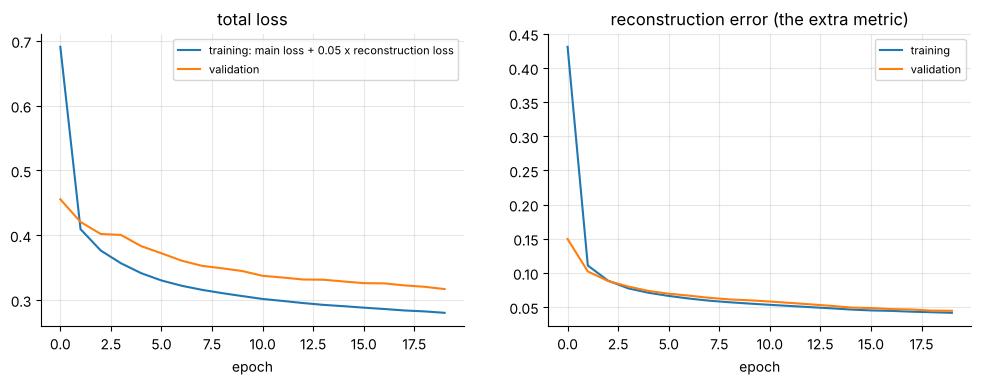

total loss  : 0.6910 -> 0.2802  (falls: True)
recon error : 0.4311 -> 0.0416  (falls: True)


In [37]:
class ReconstructingRegressor(keras.Model):
    def __init__(self, output_dim=1, **kwargs):
        super().__init__(**kwargs)
        self.output_dim = output_dim
        self.hidden = [layers.Dense(30, activation="selu", kernel_initializer="lecun_normal") for _ in range(5)]
        self.out = layers.Dense(output_dim)
        self.recon_metric = keras.metrics.Mean(name="recon_error")       # replaces add_metric()
    def build(self, batch_input_shape):
        n_inputs = batch_input_shape[-1]
        self.reconstruct = layers.Dense(n_inputs)                          # its size depends on the (unknown until now) input size
    def call(self, inputs):
        Z = inputs
        for layer in self.hidden:
            Z = layer(Z)
        reconstruction = self.reconstruct(Z)
        recon_loss = tf.reduce_mean(tf.square(reconstruction - inputs))
        self.add_loss(0.05 * recon_loss)
        self.recon_metric.update_state(recon_loss)
        return self.out(Z)

reset_seed(); net58 = ReconstructingRegressor()
h58 = fit_and_score("ReconstructingRegressor", net58)
print("history keys:", list(h58.history))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(h58.history["loss"], label="training: main loss + 0.05 x reconstruction loss"); axes[0].plot(h58.history["val_loss"], label="validation"); axes[0].set_title("total loss"); axes[0].legend(fontsize=8)
axes[1].plot(h58.history["recon_error"], label="training"); axes[1].plot(h58.history["val_recon_error"], label="validation"); axes[1].set_title("reconstruction error (the extra metric)"); axes[1].legend(fontsize=8)
[a.set_xlabel("epoch") for a in axes]; plt.show()
print(f"total loss  : {h58.history['loss'][0]:.4f} -> {h58.history['loss'][-1]:.4f}  (falls: {h58.history['loss'][-1] < h58.history['loss'][0]})")
print(f"recon error : {h58.history['recon_error'][0]:.4f} -> {h58.history['recon_error'][-1]:.4f}  (falls: {h58.history['recon_error'][-1] < h58.history['recon_error'][0]})")

In [38]:
tbl5 = pd.DataFrame(results5); display(tbl5)
base = tbl5.loc[0, "test MSE"]
for _, r in tbl5.iloc[1:].iterrows():
    diff = 100 * (r["test MSE"] - base) / base
    print(f"{r['model']:36s} test MSE {r['test MSE']:.4f}  ->  {abs(diff):.1f}% {'better' if diff < 0 else 'worse'} than the ordinary MLP")

,model,parameters,test MAE,test MSE
0,ordinary MLP (30-30 ReLU),1231,0.3928,0.3245
1,MLP + Lambda(exp) output layer,1231,0.4206,0.3677
2,MLP made of MyDense layers,1231,0.3831,0.3105
3,MLP + MyGaussianNoise(0.1) on input,1231,0.4249,0.3772
4,ResidualRegressor,4021,0.4650,0.4176
5,ReconstructingRegressor,4269,0.3977,0.3199


MLP + Lambda(exp) output layer       test MSE 0.3677  ->  13.3% worse than the ordinary MLP
MLP made of MyDense layers           test MSE 0.3105  ->  4.3% better than the ordinary MLP
MLP + MyGaussianNoise(0.1) on input  test MSE 0.3772  ->  16.2% worse than the ordinary MLP
ResidualRegressor                    test MSE 0.4176  ->  28.7% worse than the ordinary MLP
ReconstructingRegressor              test MSE 0.3199  ->  1.4% better than the ordinary MLP


**Reading the comparison.** The custom components do their job as *building blocks* — the point of this phase is that they train, save and load correctly and behave like their built-in counterparts. How they compare with the plain MLP on this small, easy dataset is just what the table above shows; differences of a few percent are within the noise of a single run and seed, and the residual / reconstructing models have more parameters than the basic MLP.

### ✅ Phase 5 deliverable
`MyDense` ✔ · `MyGaussianNoise` ✔ · `ResidualBlock` / `ResidualRegressor` ✔ · `ReconstructingRegressor` with its extra metric ✔ · each trained on California Housing and compared with the ordinary MLP ✔

---
# Phase 6 — Computing Gradients with Autodiff

**Simple idea.** Training = nudging every weight in the direction that lowers the loss. That direction is the **gradient** (the slope of the loss with respect to each weight). Computing slopes by hand for a deep network is impossible, so TensorFlow *records* the operations you perform and replays them backwards to get all the slopes at once. The recorder is `tf.GradientTape`.

**Real-life example.** Think of a hiker who wants to go downhill in fog. The gradient is the compass telling which way is steepest *up* at the current spot; the hiker steps the opposite way. Autodiff is a surveyor who can read that compass for a million directions at the same time.

### Task 6.1 — By hand: `f(w1, w2) = 3·w1² + 2·w1·w2`

∂f/∂w1 = 6·w1 + 2·w2 and ∂f/∂w2 = 2·w1. At (w1, w2) = (5, 3): ∂f/∂w1 = 30 + 6 = **36**, ∂f/∂w2 = **10**.

### Task 6.2 — Finite differences (the numerical approximation)

In [39]:
def f(w1, w2):
    return 3 * w1 ** 2 + 2 * w1 * w2

w1, w2 = 5, 3
eps = 1e-6
fd1 = (f(w1 + eps, w2) - f(w1, w2)) / eps
fd2 = (f(w1, w2 + eps) - f(w1, w2)) / eps
print(f"finite differences (eps = 1e-6): df/dw1 = {fd1:.7f}, df/dw2 = {fd2:.7f}   (exact: 36 and 10)")

finite differences (eps = 1e-6): df/dw1 = 36.0000030, df/dw2 = 10.0000000   (exact: 36 and 10)


**Two drawbacks:** (1) it is only **approximate** (we see `36.000003`, not `36`; a smaller `eps` eventually makes it worse because of round-off); (2) it needs **at least one extra function call per parameter** — a network with 10 million weights would need 10 million forward passes for a single gradient. Hopeless.

### Task 6.3 — With `tf.GradientTape`

In [40]:
w1, w2 = tf.Variable(5.), tf.Variable(3.)
with tf.GradientTape() as tape:
    z = f(w1, w2)
gradients = tape.gradient(z, [w1, w2])
tape_values = [float(g) for g in gradients]
display(pd.DataFrame({"by hand": [36.0, 10.0], "finite differences": [round(fd1, 6), round(fd2, 6)], "GradientTape": tape_values}, index=["df/dw1", "df/dw2"]))
print("tape.gradient ->", [g.numpy() for g in gradients])

,by hand,finite differences,GradientTape
df/dw1,36.0,36.000003,36.0
df/dw2,10.0,10.000000,10.0


tape.gradient -> [np.float32(36.0), np.float32(10.0)]


**Why does this scale?** The tape records the forward pass once; `gradient()` then runs **one reverse pass** through the recorded operations. The cost is about 2–3× one forward pass **regardless of the number of variables** (reverse-mode autodiff) — which is why training a network with millions of weights is feasible.

### Task 6.4 — A tape can be used only once… unless it is persistent

In [41]:
with tf.GradientTape() as tape:
    z = f(w1, w2)
dz_dw1 = tape.gradient(z, w1)
try:
    dz_dw2 = tape.gradient(z, w2)                      # second call on a non-persistent tape
except RuntimeError as ex:
    print("RuntimeError:", str(ex)[:110], "...")

with tf.GradientTape(persistent=True) as tape:
    z = f(w1, w2)
dz_dw1 = tape.gradient(z, w1); dz_dw2 = tape.gradient(z, w2)       # both work
print("persistent tape ->", float(dz_dw1), float(dz_dw2))
del tape                                                           # free the memory the tape holds

RuntimeError: A non-persistent GradientTape can only be used to compute one set of gradients (or jacobians) ...
persistent tape -> 36.0 10.0


A normal tape frees its memory after the first `gradient()` call (to save memory); `persistent=True` keeps it so you can call `gradient()` several times — then you must `del tape` yourself.

### Task 6.5 — The tape tracks only *variables*; `tape.watch()` for the rest

In [42]:
c1, c2 = tf.constant(5.), tf.constant(3.)
with tf.GradientTape() as tape:
    z = f(c1, c2)
print("gradients w.r.t. constants :", tape.gradient(z, [c1, c2]))

with tf.GradientTape() as tape:
    tape.watch(c1); tape.watch(c2)
    z = f(c1, c2)
print("after tape.watch(...)      :", [float(g) for g in tape.gradient(z, [c1, c2])])

# use case: penalize a model whose output changes a lot when the input changes a little (gradient of the output w.r.t. the INPUT)
reset_seed(); model_w = housing_mlp(); model_w.fit(X_train_h, y_train_h, epochs=ep(3), batch_size=64, verbose=0)
x_in = tf.constant(X_test_h[:256])
with tf.GradientTape() as tape:
    tape.watch(x_in)
    out = model_w(x_in)
d_out_d_in = tape.gradient(out, x_in)                                    # one slope per input feature per instance
print("\nsensitivity of the housing model's price to each input (mean |d price / d feature|):")
print(pd.Series(np.abs(d_out_d_in.numpy()).mean(0), index=["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population", "AveOccup", "Latitude", "Longitude"]).round(3).to_dict())
print("a regularizer could add  mean(d_out_d_in ** 2)  to the loss to discourage over-sensitive models")

gradients w.r.t. constants : [None, None]
after tape.watch(...)      : [36.0, 10.0]



sensitivity of the housing model's price to each input (mean |d price / d feature|):
{'MedInc': 0.7900000214576721, 'HouseAge': 0.3449999988079071, 'AveRooms': 0.3160000145435333, 'AveBedrms': 0.4819999933242798, 'Population': 0.2919999957084656, 'AveOccup': 1.6929999589920044, 'Latitude': 1.062999963760376, 'Longitude': 1.0420000553131104}
a regularizer could add  mean(d_out_d_in ** 2)  to the loss to discourage over-sensitive models


### Task 6.6 — Two efficiency tips

1. **Keep only the strictly necessary computations inside the `with tf.GradientTape()` block** — everything inside is recorded and costs memory and time.
2. For work that must not be differentiated or recorded (logging, a side computation), **pause recording** with `tape.stop_recording()`.

In [43]:
w1, w2 = tf.Variable(5.), tf.Variable(3.)
with tf.GradientTape() as tape:
    z = f(w1, w2)
    with tape.stop_recording():
        side = w1 * 1000.                       # a side computation: NOT recorded
    z_total = z + side                          # `side` now acts like a plain constant
print("with stop_recording    : dz_total/dw1 =", float(tape.gradient(z_total, w1)), "(only the f(w1, w2) part)")
with tf.GradientTape() as tape:
    z = f(w1, w2); side = w1 * 1000.; z_total = z + side
print("without stop_recording : dz_total/dw1 =", float(tape.gradient(z_total, w1)), "(36 + 1000: the side computation counts too)")

with stop_recording    : dz_total/dw1 = 36.0 (only the f(w1, w2) part)
without stop_recording : dz_total/dw1 = 1036.0 (36 + 1000: the side computation counts too)


### Task 6.7 — The gradient of a *vector*, and the Jacobian

If you ask for the gradient of a **vector** `y`, TensorFlow differentiates its **sum**. To get one gradient per output (a *Jacobian*), use `tape.jacobian()`. (Second-order derivatives — the Hessian — are possible by nesting tapes, but they are rarely needed in practice.)

In [44]:
v = tf.Variable([1., 2., 3.])
with tf.GradientTape(persistent=True) as tape:
    y = tf.stack([v[0] * v[1], v[1] * v[2]])             # two outputs: y0 = v0*v1, y1 = v1*v2
print("y =", y.numpy())
print("tape.gradient(y, v) =", tape.gradient(y, v).numpy(), "   <- gradient of the SUM y0 + y1:  [v1, v0+v2, v1] = [2, 4, 2]")
print("tape.jacobian(y, v) =\n", tape.jacobian(y, v).numpy(), "\n   row 0 = gradient of y0 = [v1, v0, 0];  row 1 = gradient of y1 = [0, v2, v1]")
del tape

x = tf.Variable(2.0)
with tf.GradientTape() as outer:
    with tf.GradientTape() as inner:
        y = x ** 3
    dy = inner.gradient(y, x)                              # 3x^2 = 12
d2y = outer.gradient(dy, x)                                # 6x   = 12
print(f"\nsecond derivative of x^3 at x=2 (nested tapes): first = {float(dy):.0f}, second = {float(d2y):.0f}")

y = [2. 6.]
tape.gradient(y, v) = [2. 4. 2.]    <- gradient of the SUM y0 + y1:  [v1, v0+v2, v1] = [2, 4, 2]
tape.jacobian(y, v) =
 [[2. 1. 0.]
 [0. 3. 2.]] 
   row 0 = gradient of y0 = [v1, v0, 0];  row 1 = gradient of y1 = [0, v2, v1]

second derivative of x^3 at x=2 (nested tapes): first = 12, second = 12


### Task 6.8 — Blocking a gradient with `tf.stop_gradient()`

`tf.stop_gradient(x)` returns `x` unchanged in the forward pass but stops the backward pass: no gradient flows *through* it.

In [45]:
def f_stop(w1, w2):
    return 3 * w1 ** 2 + tf.stop_gradient(2 * w1 * w2)

w1, w2 = tf.Variable(5.), tf.Variable(3.)
with tf.GradientTape() as tape:
    z = f_stop(w1, w2)
gradients = tape.gradient(z, [w1, w2])
print("forward value unchanged :", float(z), "==", float(f(w1, w2)))
print("gradients               :", [None if g is None else float(g) for g in gradients], "  <- [30., None]: the 2*w1*w2 term no longer contributes")

forward value unchanged : 105.0 == 105.0
gradients               : [30.0, None]   <- [30., None]: the 2*w1*w2 term no longer contributes


### Task 6.9 — The numerical-stability problem, and `@tf.custom_gradient`

The softplus `log(exp(z) + 1)` is fine mathematically, but at `z = 100` in 32-bit floats `exp(100)` overflows to `inf`, and the automatic gradient becomes `inf / inf = NaN`.

In [46]:
x = tf.Variable([100.])
with tf.GradientTape() as tape:
    z = my_softplus(x)
print("forward my_softplus(100) =", z.numpy(), "| gradient =", tape.gradient(z, [x]), "  <- NaN (inf / inf)")

forward my_softplus(100) = [inf] | gradient = [<tf.Tensor: shape=(1,), dtype=float32, numpy=array([nan], dtype=float32)>]   <- NaN (inf / inf)


The true derivative of softplus is the logistic function `1 / (1 + 1/exp(z))`, which is perfectly stable. We hand TensorFlow this formula with `@tf.custom_gradient`: the decorated function returns **(the forward result, a function that computes the gradients)**.

**What is `grad`?** By the chain rule, the gradient of the final loss with respect to this function's *input* equals (the gradient of the loss with respect to its *output*, which TensorFlow passes in as `grad`) × (this function's own local derivative). So our gradient function just multiplies `grad` by the local derivative.

In [47]:
@tf.custom_gradient
def my_better_softplus(z):
    exp = tf.exp(z)
    def my_softplus_gradients(grad):
        return grad / (1 + 1 / exp)
    return tf.math.log(exp + 1), my_softplus_gradients

x = tf.Variable([100.])
with tf.GradientTape() as tape:
    z = my_better_softplus(x)
print("custom gradient at 100 :", tape.gradient(z, [x]), "  <- fixed (should be 1.0)   | forward value:", z.numpy(), "<- still overflows to inf")

# the forward value can be fixed too: for large z, softplus(z) is almost exactly z
@tf.custom_gradient
def my_best_softplus(z):
    exp = tf.exp(z)
    def my_softplus_gradients(grad):
        return grad / (1 + 1 / exp)
    return tf.where(z > 30., z, tf.math.log(exp + 1.)), my_softplus_gradients

pts = tf.Variable([-100., -5., 0., 5., 100.])
with tf.GradientTape(persistent=True) as t1:
    ours = my_best_softplus(pts); builtin = tf.nn.softplus(pts)
display(pd.DataFrame({"z": pts.numpy(), "my_best_softplus(z)": ours.numpy(), "tf.nn.softplus(z)": builtin.numpy(),
                      "our gradient": t1.gradient(ours, pts).numpy(), "built-in gradient": t1.gradient(builtin, pts).numpy()}))
del t1

custom gradient at 100 : [<tf.Tensor: shape=(1,), dtype=float32, numpy=array([1.], dtype=float32)>]   <- fixed (should be 1.0)   | forward value: [inf] <- still overflows to inf


,z,my_best_softplus(z),tf.nn.softplus(z),our gradient,built-in gradient
0,-100.0,0.000000,0.000000,0.000000,0.000000
1,-5.0,0.006715,0.006715,0.006693,0.006693
2,0.0,0.693147,0.693147,0.500000,0.500000
3,5.0,5.006715,5.006715,0.993307,0.993307
4,100.0,100.000000,100.000000,1.000000,1.000000


### ✅ Phase 6 deliverable
Hand-derived, finite-difference and `GradientTape` gradients side by side ✔ · persistent tape, `watch`, `stop_recording`, Jacobian ✔ · `stop_gradient` giving `[30., None]` ✔ · the `NaN` → fixed custom-gradient example ✔

---
# Phase 7 — Custom Training Loops

**Simple idea.** `fit()` is an automatic gearbox: perfect for 95 % of drives. A custom loop is a manual gearbox: you choose every gear change yourself. You pay with more code and more chances for bugs, but you can do things `fit()` cannot.

### Task 7.1 — When do you need one?

`fit()` is enough **unless** you need, for example:
* **two (or more) different optimizers** — e.g. the Wide & Deep paper (Task 14) trains the *wide* path and the *deep* path with different optimizers;
* gradient transformations beyond simple clipping;
* or you simply want full transparency about what happens.

Custom loops are longer, more error-prone and harder to maintain, so in a team prefer `fit()` unless you need the flexibility.

### Task 7.2 – 7.3 — The model, the helpers and the hyper-parameters

In [48]:
l2 = keras.regularizers.l2(0.05)
reset_seed()
model7 = keras.Sequential([layers.Input((8,)),
                           layers.Dense(30, activation="elu", kernel_initializer="he_normal", kernel_regularizer=l2),
                           layers.Dense(1, kernel_regularizer=l2)])                 # NOT compiled: we do everything ourselves

def random_batch(X, y, batch_size=32):
    idx = np.random.randint(len(X), size=batch_size)
    return X[idx], y[idx]

def print_status_bar(step, total, loss, metrics=None, end="\n"):
    metrics = " - ".join(f"{m.name}: {float(m.result()):.4f}" for m in [loss] + (metrics or []))
    print(f"{step}/{total} - " + metrics, end=end)

def mean_squared_error(y_true, y_pred):                  # one loss per instance (Keras 3 note: written out here because the old keras.losses.mean_squared_error alias is gone)
    return tf.reduce_mean(tf.square(y_true - y_pred), axis=-1)

n_epochs, batch_size = ep(5), 32
n_steps = len(X_train_h) // batch_size
optimizer = keras.optimizers.Nadam(learning_rate=0.01)
loss_fn = mean_squared_error
mean_loss = keras.metrics.Mean(name="loss")
metrics = [keras.metrics.MeanAbsoluteError()]
print(f"{n_epochs} epochs x {n_steps} steps of {batch_size} instances")

5 epochs x 387 steps of 32 instances


### Task 7.4 — The loop

For every step: **sample a batch → record the forward pass in a tape → compute the loss (main loss + regularization losses) → get the gradients → apply them → update the metrics.** Notes:

* `model(X_batch, training=True)` — tells dropout/BN layers they are in training mode.
* `tf.reduce_mean(loss_fn(...))` — reduce here; this is also where you would multiply by per-instance weights.
* `tf.add_n([main_loss] + model.losses)` — `model.losses` holds the regularization terms (ℓ2 here) which `fit()` would have added for you.
* `tape.gradient(loss, model.trainable_variables)` — **trainable** variables only (not BN moving averages etc.).
* At the end of an epoch print a final status line and `reset_state()` every metric *(Keras 3 spelling; `reset_states()` in old Keras)*.
* Task 7.7 — a **validation pass** at the end of each epoch, with `training=False`.

In [49]:
history7 = []
reset_seed()
for epoch in range(1, n_epochs + 1):
    print(f"Epoch {epoch}/{n_epochs}")
    for step in range(1, n_steps + 1):
        X_batch, y_batch = random_batch(X_train_h, y_train_h)
        with tf.GradientTape() as tape:
            y_pred = model7(X_batch, training=True)
            main_loss = tf.reduce_mean(loss_fn(y_batch, y_pred))
            loss = tf.add_n([main_loss] + model7.losses)
        gradients = tape.gradient(loss, model7.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model7.trainable_variables))
        mean_loss(loss)
        for metric in metrics:
            metric(y_batch, y_pred)
        if step % 100 == 0: print_status_bar(step, n_steps, mean_loss, metrics, end="\n")
    print_status_bar(n_steps, n_steps, mean_loss, metrics, end="")
    # validation pass (no training mode, no regularization term)
    y_val = model7(X_valid_h, training=False)
    val_mse = float(tf.reduce_mean(loss_fn(y_valid_h, y_val))); val_mae = float(tf.reduce_mean(tf.abs(y_valid_h - y_val)))
    print(f" - val_mse: {val_mse:.4f} - val_mae: {val_mae:.4f}")
    history7.append({"epoch": epoch, "train loss (incl. l2)": float(mean_loss.result()), "train MAE": float(metrics[0].result()), "val MSE": val_mse, "val MAE": val_mae})
    for metric in [mean_loss] + metrics:
        metric.reset_state()
display(pd.DataFrame(history7).round(4))

Epoch 1/5


100/387 - loss: 2.9669 - mean_absolute_error: 0.6995


200/387 - loss: 1.9339 - mean_absolute_error: 0.6040


300/387 - loss: 1.5108 - mean_absolute_error: 0.5728


387/387 - loss: 1.3263 - mean_absolute_error: 0.5658 - val_mse: 0.5065 - val_mae: 0.5257
Epoch 2/5


...

100/387 - loss: 0.6327 - mean_absolute_error: 0.5206


200/387 - loss: 0.6365 - mean_absolute_error: 0.5262


300/387 - loss: 0.6354 - mean_absolute_error: 0.5227


387/387 - loss: 0.6420 - mean_absolute_error: 0.5249 - val_mse: 0.5119 - val_mae: 0.5428


,epoch,train loss (incl. l2),train MAE,val MSE,val MAE
0,1,1.3263,0.5658,0.5065,0.5257
1,2,0.6448,0.5294,0.5125,0.5162
2,3,0.6450,0.5290,0.5234,0.5256
3,4,0.6428,0.5272,0.5137,0.5235
4,5,0.6420,0.5249,0.5119,0.5428


### Task 7.5 — Clipping and other gradient transformations

`clipnorm` / `clipvalue` given to the **optimizer** still work in a custom loop, because `apply_gradients()` applies them. Any **other** gradient transformation goes **between `tape.gradient()` and `apply_gradients()`** — there you hold the gradients as a plain list you can modify (scale, add noise, mask…).

In [50]:
reset_seed(); probe = keras.Sequential([layers.Input((8,)), layers.Dense(30, activation="elu"), layers.Dense(1)])
Xb, yb = X_train_h[:256], y_train_h[:256]
for name, opt in [("SGD lr=1.0, no clipping", keras.optimizers.SGD(learning_rate=1.0)), ("SGD lr=1.0, clipnorm=0.1", keras.optimizers.SGD(learning_rate=1.0, clipnorm=0.1))]:
    m = keras.models.clone_model(probe); m.set_weights(probe.get_weights()); before = [v.numpy().copy() for v in m.trainable_variables]
    with tf.GradientTape() as tape:
        loss_ = tf.reduce_mean(mean_squared_error(yb, m(Xb, training=True)))
    grads = tape.gradient(loss_, m.trainable_variables)
    # ---- any other gradient transformation goes HERE, e.g.:  grads = [g * 0.5 for g in grads]
    opt.apply_gradients(zip(grads, m.trainable_variables))
    step_sizes = [float(np.linalg.norm(v.numpy() - b)) for v, b in zip(m.trainable_variables, before)]
    print(f"{name:28s} -> largest parameter change of any tensor in one step: {max(step_sizes):.4f}")

SGD lr=1.0, no clipping      -> largest parameter change of any tensor in one step: 4.6303
SGD lr=1.0, clipnorm=0.1     -> largest parameter change of any tensor in one step: 0.1000


With `clipnorm=0.1` and learning rate 1.0, no tensor can move by more than 0.1 in one step — the optimizer clipped the gradients even though we never called `fit()`.

### Task 7.6 — Constraints must be applied by hand (in the classic loop)

If a layer has a **constraint**, apply it right after `apply_gradients()`:

```python
for variable in model.variables:
    if variable.constraint is not None:
        variable.assign(variable.constraint(variable))
```
*(Keras 3 note: its optimizer already does this inside `apply_gradients()`. The demo below uses a hand-written SGD step, which bypasses the optimizer, to show what the loop above would otherwise be missing.)*

In [51]:
def make_cmodel():
    reset_seed()                                                                  # same starting weights every time
    return keras.Sequential([layers.Input((8,)), layers.Dense(30, activation="relu", kernel_constraint=my_positive_weights), layers.Dense(1)])
cmodel = make_cmodel()
Xb, yb = X_train_h[:512], y_train_h[:512]
def manual_sgd_step(model, lr=0.05, apply_constraints=False):
    with tf.GradientTape() as tape:
        loss_ = tf.reduce_mean(mean_squared_error(yb, model(Xb, training=True)))
    for v, g in zip(model.trainable_variables, tape.gradient(loss_, model.trainable_variables)):
        v.assign_sub(lr * g)                                           # our own update rule, no optimizer involved
    if apply_constraints:
        for variable in model.variables:
            if variable.constraint is not None:
                variable.assign(variable.constraint(variable))
for flag in (False, True):
    m = make_cmodel()
    for _ in range(5): manual_sgd_step(m, apply_constraints=flag)
    print(f"constraints applied by hand: {str(flag):5s} -> smallest weight in the constrained layer = {m.layers[0].kernel.numpy().min():+.4f}")
print("variables that carry a constraint:", [v.name for v in cmodel.variables if v.constraint is not None])

constraints applied by hand: False -> smallest weight in the constrained layer = -0.4042
constraints applied by hand: True  -> smallest weight in the constrained layer = +0.0000
variables that carry a constraint: ['kernel']


### Task 7.7 — What the loop does *not* give you for free

| `fit()` feature | In a custom loop |
|---|---|
| **Training / inference mode** (Dropout, BatchNorm) | You must pass `training=True` while training and `training=False` when evaluating (and propagate it to your own layers). |
| **Validation** | You write it (we did, at the end of each epoch). |
| **Callbacks** (early stopping, checkpoints, TensorBoard) | You write them (`if val < best: model.save(...)`). |
| **Learning-rate schedules** | You update `optimizer.learning_rate` yourself. |
| **Progress bar, history** | You write them (`print_status_bar`, the `history7` list). |
| **Shuffling & epoch bookkeeping** | You write them (or use `tf.data`). |
| **Distribution strategies / sample weights** | You write them. |

### Task 7.8 — The sampling caveat

`random_batch` draws instances **with replacement**, so within one "epoch" of `n` steps some instances are processed more than once and some never. This is fine in practice, but a proper `tf.data` pipeline (shuffle once per epoch, every instance exactly once) is the better approach:

In [52]:
N = len(X_train_h); seen = np.zeros(N, bool)
for _ in range(n_steps): seen[np.random.randint(N, size=32)] = True
print(f"after {n_steps} random batches of 32 ({n_steps * 32} draws for {N} instances): {np.mean(~seen):.1%} of the instances were never used in this 'epoch'  (theory: 1/e = {np.exp(-1):.1%} for a full-size epoch)")

after 387 random batches of 32 (12384 draws for 12384 instances): 37.1% of the instances were never used in this 'epoch'  (theory: 1/e = 36.8% for a full-size epoch)


### Task 7.9 — Two optimizers: one for the lower layers, one for the upper layers

We keep a list of *(optimizer, variables)* pairs. After computing all gradients with one tape, each optimizer applies only the gradients of **its** variables. To verify that **both groups are updating**, we track (a) the learning curves and (b) how far each group's weights moved from their starting values.

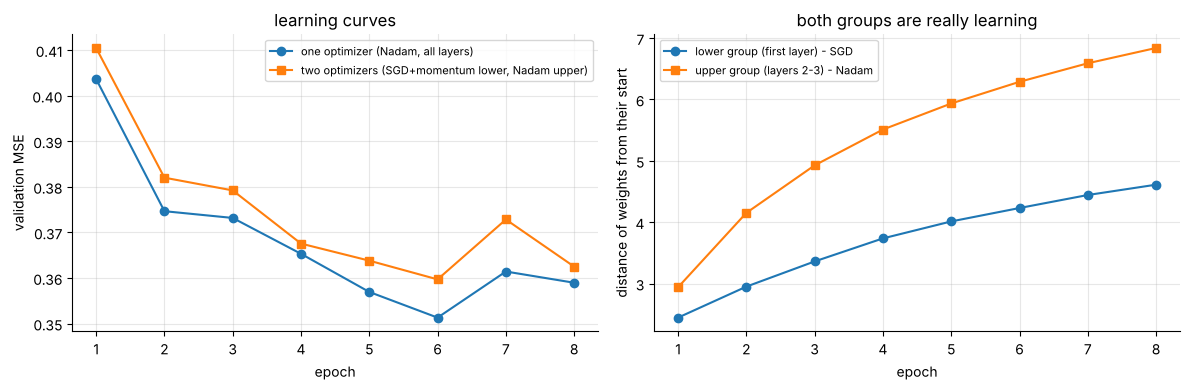

,epoch,train loss,val MSE,group 0: distance moved,group 1: distance moved
0,1,0.6678,0.4105,2.4454,2.9400
1,2,0.5208,0.3820,2.9506,4.1518
2,3,0.4840,0.3792,3.3611,4.9268
3,4,0.4558,0.3676,3.7364,5.5101
4,5,0.4468,0.3638,4.0130,5.9346
5,6,0.4324,0.3597,4.2314,6.2878
6,7,0.4316,0.3728,4.4434,6.5899
7,8,0.4138,0.3625,4.6116,6.8393


final validation MSE: one optimizer 0.3590 | two optimizers 0.3625


In [53]:
def run_custom_loop(model, groups, n_epochs, batch_size=32, lr_decay=1.0, seed=SEED):
    # groups = [(optimizer, [variables]), ...] -- every trainable variable should be in exactly one group
    reset_seed(seed); np.random.seed(seed)
    start = {id(v): v.numpy().copy() for _, vs in groups for v in vs}
    mean_loss_, mae_ = keras.metrics.Mean(name="loss"), keras.metrics.MeanAbsoluteError(); rows = []
    for epoch in range(1, n_epochs + 1):
        for step in range(n_steps):
            Xb_, yb_ = random_batch(X_train_h, y_train_h, batch_size)
            with tf.GradientTape() as tape:
                pred = model(Xb_, training=True)
                loss_ = tf.add_n([tf.reduce_mean(mean_squared_error(yb_, pred))] + model.losses)
            grads = tape.gradient(loss_, model.trainable_variables)
            gmap = {id(v): g for v, g in zip(model.trainable_variables, grads)}
            for opt, vs in groups:
                opt.apply_gradients([(gmap[id(v)], v) for v in vs])
            mean_loss_(loss_); mae_(yb_, pred)
        yv = model(X_valid_h, training=False)
        row = {"epoch": epoch, "train loss": float(mean_loss_.result()), "val MSE": float(tf.reduce_mean(mean_squared_error(y_valid_h, yv)))}
        for gi, (_, vs) in enumerate(groups):
            row[f"group {gi}: distance moved"] = float(np.sqrt(sum(np.sum((v.numpy() - start[id(v)]) ** 2) for v in vs)))
        rows.append(row); mean_loss_.reset_state(); mae_.reset_state()
        for opt, _ in groups: opt.learning_rate = float(opt.learning_rate) * lr_decay            # a learning-rate schedule, by hand
    return pd.DataFrame(rows)

def three_layer_model():
    reset_seed()
    return keras.Sequential([layers.Input((8,)),
                             layers.Dense(40, activation="elu", kernel_initializer="he_normal", kernel_regularizer=keras.regularizers.l2(0.001)),
                             layers.Dense(40, activation="elu", kernel_initializer="he_normal", kernel_regularizer=keras.regularizers.l2(0.001)),
                             layers.Dense(1)])

EP7 = ep(8)
m_one = three_layer_model(); hist_one = run_custom_loop(m_one, [(keras.optimizers.Nadam(learning_rate=0.005), m_one.trainable_variables)], EP7, lr_decay=0.9)
m_two = three_layer_model()
lower, upper = m_two.layers[0].trainable_variables, m_two.layers[1].trainable_variables + m_two.layers[2].trainable_variables
hist_two = run_custom_loop(m_two, [(keras.optimizers.SGD(learning_rate=0.01, momentum=0.9), lower), (keras.optimizers.Nadam(learning_rate=0.005), upper)], EP7, lr_decay=0.9)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_one["epoch"], hist_one["val MSE"], "o-", label="one optimizer (Nadam, all layers)"); axes[0].plot(hist_two["epoch"], hist_two["val MSE"], "s-", label="two optimizers (SGD+momentum lower, Nadam upper)")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("validation MSE"); axes[0].set_title("learning curves"); axes[0].legend(fontsize=8)
axes[1].plot(hist_two["epoch"], hist_two["group 0: distance moved"], "o-", label="lower group (first layer) - SGD"); axes[1].plot(hist_two["epoch"], hist_two["group 1: distance moved"], "s-", label="upper group (layers 2-3) - Nadam")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("distance of weights from their start"); axes[1].set_title("both groups are really learning"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
display(hist_two.round(4))
print(f"final validation MSE: one optimizer {hist_one['val MSE'].iloc[-1]:.4f} | two optimizers {hist_two['val MSE'].iloc[-1]:.4f}")

Both curves go down, and the "distance moved" of **both** groups keeps growing — proof that each optimizer is updating its own set of variables. (Which combination is best is a tuning question; the point is that the custom loop makes it possible at all.)

### Every `fit()` feature we had to re-implement by hand

1. The **epoch / batch loops** and the sampling of batches (and shuffling).
2. Putting the forward pass inside a **`GradientTape`**, computing gradients and calling **`apply_gradients`**.
3. **Adding the regularization losses** (`tf.add_n([main_loss] + model.losses)`).
4. **Metric bookkeeping**: updating, printing and **resetting** metrics.
5. **Progress display** (`print_status_bar`) and the history list.
6. **Training vs. inference mode** (`training=True/False`).
7. **Validation** at the end of every epoch.
8. **Constraints** (in the classic loop) and the **gradient transformations** between `gradient()` and `apply_gradients()`.
9. **Learning-rate scheduling** (`optimizer.learning_rate = …`), **callbacks** such as early stopping/checkpoints, and any **multi-optimizer** logic.

### ✅ Phase 7 deliverable
A custom loop with metrics, validation and constraint handling ✔ · a two-optimizer variant with learning curves ✔ · the list of re-implemented `fit()` features ✔

---
# Phase 8 — TensorFlow Functions, Graphs & Capstone

**Simple idea.** Python runs your code line by line, which is flexible but slow. A **TF Function** is like recording a cooking show: the first time, TensorFlow watches your Python function once and writes down the *recipe* (a **graph** of operations). From then on it follows the recipe directly, skipping Python — faster, optimizable, and exportable.

**Real-life example.** A taxi driver who follows the satnav step by step (eager mode) versus a delivery company that plans the whole route once, removes pointless detours, and sends several vans out in parallel (graph mode).

### Task 8.1 — Turning `cube(x) = x ** 3` into a TF Function

In [54]:
def cube(x):
    return x ** 3

tf_cube = tf.function(cube)                     # as a function call ...
@tf.function                                    # ... or as a decorator
def tf_cube_decorated(x):
    return x ** 3

print("plain Python function  : cube(2) =", cube(2), "| cube(tf.constant(2.0)) =", cube(tf.constant(2.0)).numpy())
print("TF Function            : tf_cube(2) =", tf_cube(2).numpy(), "-> a", type(tf_cube(2)).__name__, "| tf_cube(tf.constant(2.0)) =", tf_cube(tf.constant(2.0)).numpy())
print("decorator version      :", tf_cube_decorated(tf.constant(3.0)).numpy())
print("original Python function still available: tf_cube.python_function(2) =", tf_cube.python_function(2))

plain Python function  : cube(2) = 8 | cube(tf.constant(2.0)) = 8.0
TF Function            : tf_cube(2) = 8 -> a EagerTensor | tf_cube(tf.constant(2.0)) = 8.0
decorator version      : 27.0
original Python function still available: tf_cube.python_function(2) = 8


### Task 8.2 — What TensorFlow does with the graph

* **Prunes** nodes that do not contribute to the result,
* **simplifies** expressions (e.g. `1 + 2` → `3`),
* runs **independent operations in parallel**.

For a tiny function like `cube` there is nothing to optimize — the TF Function is even a little *slower* (it pays an overhead per call):

In [55]:
concrete = tf_cube.get_concrete_function(tf.constant(2.0))
print("operations in the graph of cube:", [op.type for op in concrete.graph.get_operations()])

x = tf.constant(2.0); n = 2000
t0 = time.perf_counter(); [cube(x) for _ in range(n)]; t_eager = time.perf_counter() - t0
t0 = time.perf_counter(); [tf_cube(x) for _ in range(n)]; t_graph = time.perf_counter() - t0
print(f"{n} calls:  eager {1000 * t_eager:.0f} ms | TF Function {1000 * t_graph:.0f} ms   (trivial work -> no gain, as expected)")

operations in the graph of cube: ['Placeholder', 'Const', 'Pow', 'Identity']


2000 calls:  eager 36 ms | TF Function 434 ms   (trivial work -> no gain, as expected)


### Task 8.3 — Keras does this for you

Keras automatically converts your custom losses, metrics, layers and models to TF Functions, so most of this is invisible. To switch it off (e.g. to debug with `print` and breakpoints, or to use arbitrary Python), compile with **`run_eagerly=True`**. *(Keras 3 note: the old `dynamic=True` argument of layers/models no longer exists; `run_eagerly=True` is the switch — we use it in Exercise 12.)*

### Task 8.4 — Polymorphism and graph caching

A TF Function traces a **new graph for every new input signature**:
* for **tensor** arguments, a new graph per distinct *shape and dtype*;
* for **Python number** arguments, a new graph per distinct *value*.

Many distinct Python values therefore create many graphs and waste memory — reserve Python values for arguments with few distinct values (like a hyper-parameter). We can count the traces because a Python side effect (appending to a list) happens **only while tracing**:

In [56]:
trace_log = []
@tf.function
def double(x):
    trace_log.append("traced")                       # Python side effect -> runs only when a graph is (re)built
    return x * 2

steps = [("tf.constant(1.0)                 (first call)", lambda: double(tf.constant(1.0))),
         ("tf.constant(2.0)                 (same shape + dtype)", lambda: double(tf.constant(2.0))),
         ("tf.constant([1., 2.])            (new shape)", lambda: double(tf.constant([1., 2.]))),
         ("tf.constant(1)                   (new dtype: int32)", lambda: double(tf.constant(1))),
         ("Python number 1                  (new value)", lambda: double(1)),
         ("Python number 2                  (new value)", lambda: double(2)),
         ("Python number 3                  (new value)", lambda: double(3)),
         ("Python number 1 again            (cached)", lambda: double(1))]
rows = []
for label, call in steps:
    before = len(trace_log); call(); rows.append({"call": label, "new graph traced?": "YES" if len(trace_log) > before else "no", "graphs so far": len(trace_log)})
display(pd.DataFrame(rows))

,call,new graph traced?,graphs so far
0,tf.constant(1.0) (first call),YES,1
1,tf.constant(2.0) (same shape + dtype),no,1
2,"tf.constant([1., 2.]) (new shape)",YES,2
3,tf.constant(1) (new dtype: int32),YES,3
4,Python number 1 (new value),YES,4
5,Python number 2 (new value),YES,5
6,Python number 3 (new value),YES,6
7,Python number 1 again (cached),no,6


### Task 8.5 — AutoGraph and tracing

* **AutoGraph** reads the *source code* of your function and rewrites Python control flow (`for`, `while`, `if`) into TensorFlow control flow (`tf.while_loop`, `tf.cond`) — **when the condition/iterable is a tensor**.
* **Tracing** then runs the rewritten function with *symbolic* tensors in graph mode: each TF operation adds a node to the graph instead of computing anything.

In [57]:
@tf.function
def sum_squares(n):
    s = 0
    for i in tf.range(n):                # loop over a TENSOR -> becomes a tf.while_loop
        s += i ** 2
    return s

print("sum_squares(10) =", sum_squares(tf.constant(10)).numpy(), "(0^2 + ... + 9^2 = 285)")
print("\nthe code AutoGraph generated:\n")
print(tf.autograph.to_code(sum_squares.python_function))

sum_squares(10) = 285 (0^2 + ... + 9^2 = 285)

the code AutoGraph generated:

def tf__sum_squares(n):
    with ag__.FunctionScope('sum_squares', 'fscope', ag__.ConversionOptions(recursive=True, user_requested=True, optional_features=(), internal_convert_user_code=True)) as fscope:
        do_return = False
        retval_ = ag__.UndefinedReturnValue()
        s = 0

        def get_state():
            return (s,)

        def set_state(vars_):
            nonlocal s
            s, = vars_

        def loop_body(itr):
            nonlocal s
            i = itr
            s = ag__.ld(s)
            s += i ** 2
        i = ag__.Undefined('i')
        ag__.for_stmt(ag__.converted_call(ag__.ld(tf).range, (ag__.ld(n),), None, fscope), None, loop_body, get_state, set_state, ('s',), {'iterate_names': 'i'})
        try:
            do_return = True
            retval_ = ag__.ld(s)
        except:
            do_return = False
            raise
        return fscope.ret(retval_, do_return)



### Task 8.6 — The TF Function rules, each with a tiny demonstration

| What you write | What happens in a TF Function |
|---|---|
| `np.random.rand()` | Evaluated **once**, at tracing |
| `tf.random.uniform([])` | **New value on each call** (part of the graph) |
| `print(...)` / counter updates | Only at tracing; use `tf.print` / `tf.Variable` for per-call effects |
| `for i in range(n)` | **Unrolled** at tracing |
| `for i in tf.range(n)` | Becomes a **`tf.while_loop`** in the graph |
| Python number args | One graph per distinct value |
| Tensor args | One graph per distinct (shape, dtype) |

**Rule 1 — external libraries (NumPy, the standard library) run only during tracing.**

In [58]:
@tf.function
def numpy_random():
    return tf.constant(np.random.rand())          # NumPy runs ONCE, while the graph is being traced

@tf.function
def tf_random():
    return tf.random.uniform([])                  # a graph operation: runs on every call

print("np.random.rand() inside a TF Function, 4 calls :", [round(float(numpy_random()), 4) for _ in range(4)], " <- the same number every time")
print("tf.random.uniform([]) inside a TF Function     :", [round(float(tf_random()), 4) for _ in range(4)], " <- a new number each call")

np.random.rand() inside a TF Function, 4 calls : [0.8341, 0.8341, 0.8341, 0.8341]  <- the same number every time
tf.random.uniform([]) inside a TF Function     : [0.8355, 0.464, 0.9527, 0.3662]  <- a new number each call


**Rule 2 — Python side effects (printing, logging, counters) happen only during tracing.** To count real calls, use a `tf.Variable`; to print on every call, use `tf.print`.

In [59]:
import sys
python_counter = 0
real_calls = tf.Variable(0)

@tf.function
def instrumented(x):
    global python_counter
    python_counter += 1                               # Python side effect: only while tracing
    real_calls.assign_add(1)                          # TF operation: on every call
    print("   python print  (tracing only) -> x is a symbolic", type(x).__name__)
    tf.print("   tf.print      (every call)   -> x =", x, output_stream=sys.stdout)
    return x

for i in range(3): instrumented(tf.constant(float(i)))
print(f"after 3 calls: python_counter = {python_counter}  |  tf.Variable counter = {int(real_calls)}")

   python print  (tracing only) -> x is a symbolic SymbolicTensor


   tf.print      (every call)   -> x = 0


   tf.print      (every call)   -> x = 1


   tf.print      (every call)   -> x = 2


after 3 calls: python_counter = 1  |  tf.Variable counter = 3


**Rule 3 — `tf.py_function()` wraps arbitrary Python code** (any library, any side effect) but it is **slow** (it leaves the graph for the Python interpreter) and **not portable** (a saved graph cannot run it elsewhere). Use it only as a last resort.

In [60]:
@tf.function
def with_py_function(x):
    return tf.py_function(lambda v: tf.constant(np.sqrt(v.numpy()), dtype=tf.float32), [x], tf.float32)
print("tf.py_function runs ordinary Python inside the graph:", with_py_function(tf.constant(16.0)).numpy(), "(sqrt of 16)")

tf.py_function runs ordinary Python inside the graph: 4.0 (sqrt of 16)


**Rule 4 — variables must be created only on the *first* call** (best: in `build()` or outside the function) and modified with `assign()`, never rebuilt with `=`.

In [61]:
@tf.function
def creates_variable_each_time(x):
    v = tf.Variable(0.0)                              # a NEW variable on every trace -> not allowed
    return x + v

try: creates_variable_each_time(tf.constant(1.0))
except ValueError as ex: print("ValueError:", str(ex).replace("\n", " ")[:150], "...")

class Counter:
    def __init__(self): self.v = None
    @tf.function
    def __call__(self, x):
        if self.v is None:                            # created only on the first trace
            self.v = tf.Variable(0.0)
        self.v.assign_add(x)                          # modified with assign_add, not "="
        return self.v
c = Counter(); c(tf.constant(1.0)); c(tf.constant(2.0)); print("singleton variable created once, value after +1 and +2:", float(c.v))

ValueError: in user code:      File "/tmp/ipykernel_17818/1358375064.py", line 3, in creates_variable_each_time  *         v = tf.Variable(0.0)                    ...


singleton variable created once, value after +1 and +2: 3.0


**Rule 5 — the source code must be available** (AutoGraph reads it). A function defined with `exec()` (or in some interactive shells) has no source file, so its `if x > 0` cannot be rewritten and fails with a tensor:

In [62]:
ns = {}
exec("def no_source(x):\n    if x > 0:\n        return x * 2\n    return x", ns)
try: tf.function(ns["no_source"])(tf.constant(3.0))
except Exception as ex: print(type(ex).__name__ + ":", str(ex).replace("\n", " ")[:140], "...")

def with_source(x):
    if x > 0:                                         # AutoGraph turns this `if` into tf.cond
        return x * 2
    return x
print("same logic with source code available ->", tf.function(with_source)(tf.constant(3.0)).numpy(), tf.function(with_source)(tf.constant(-3.0)).numpy())

OperatorNotAllowedInGraphError: Using a symbolic `tf.Tensor` as a Python `bool` is not allowed. You can attempt the following resolutions to the problem: If you are running ...


same logic with source code available -> 6.0 -3.0


**Rule 6 — only loops over tensors/datasets are captured: use `for i in tf.range(x)`, not `for i in range(x)`.** A Python `range` loop is *unrolled* (one copy of the loop body per iteration — a big graph for a long loop); `tf.range` becomes a single `While` node.

In [63]:
from collections import Counter as OpCounter
@tf.function
def loop_python_range():
    s = tf.constant(0)
    for i in range(3): s += i
    return s
@tf.function
def loop_tf_range(n):
    s = tf.constant(0)
    for i in tf.range(n): s += i
    return s
g1 = OpCounter(op.type for op in loop_python_range.get_concrete_function().graph.get_operations())
g2 = OpCounter(op.type for op in loop_tf_range.get_concrete_function(tf.constant(3)).graph.get_operations())
print("for i in range(3)    -> additions in the graph:", g1["AddV2"], "| While nodes:", sum(v for k, v in g1.items() if "While" in k), " (unrolled)")
print("for i in tf.range(n) -> additions in the graph:", g2["AddV2"], "| While nodes:", sum(v for k, v in g2.items() if "While" in k), " (one loop node)")

for i in range(3)    -> additions in the graph: 3 | While nodes: 0  (unrolled)
for i in tf.range(n) -> additions in the graph: 1 | While nodes: 1  (one loop node)


**Rule 7 — prefer vectorized implementations** over loops, even `tf.while_loop`s.

In [64]:
@tf.function
def sum_with_loop(n):
    s = tf.constant(0.0)
    for i in tf.range(n): s += tf.cast(i, tf.float32) ** 2
    return s
@tf.function
def sum_vectorized(n):
    return tf.reduce_sum(tf.cast(tf.range(n), tf.float32) ** 2)
N_ = tf.constant(20000); sum_with_loop(N_); sum_vectorized(N_)                       # warm-up (tracing)
t0 = time.perf_counter(); a1 = sum_with_loop(N_).numpy(); t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); a2 = sum_vectorized(N_).numpy(); t_vec = time.perf_counter() - t0
print(f"sum of squares of 0..19999:  loop {1000 * t_loop:.1f} ms | vectorized {1000 * t_vec:.2f} ms  -> {t_loop / max(t_vec, 1e-9):.0f}x faster (same answer: {np.isclose(a1, a2, rtol=1e-4)})")

sum of squares of 0..19999:  loop 100.0 ms | vectorized 0.81 ms  -> 124x faster (same answer: True)


### Task 8.7 — Speed-up of the Phase 7 training step with `@tf.function`

We take the Phase 7 step (tape → loss + regularization → gradients → `apply_gradients` → metric) and run an epoch **eagerly** and **as a TF Function** on identical batches. The first call of the TF Function pays a one-off tracing cost; it is measured separately.

In [65]:
def make_step(model, optimizer, mean_loss_metric):
    def step(X_batch, y_batch):
        with tf.GradientTape() as tape:
            y_pred = model(X_batch, training=True)
            main_loss = tf.reduce_mean(mean_squared_error(y_batch, y_pred))
            loss = tf.add_n([main_loss] + model.losses)
        gradients = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))
        mean_loss_metric.update_state(loss)
        return loss
    return step

def fresh_phase7_model():
    reset_seed()
    return keras.Sequential([layers.Input((8,)), layers.Dense(30, activation="elu", kernel_initializer="he_normal", kernel_regularizer=l2), layers.Dense(1, kernel_regularizer=l2)])

rng_ = np.random.default_rng(0)
batches = [(tf.constant(X_train_h[i]), tf.constant(y_train_h[i])) for i in (rng_.integers(len(X_train_h), size=32) for _ in range(n_steps))]
timing = {}
for mode in ("eager (plain Python)", "@tf.function"):
    m = fresh_phase7_model(); opt = keras.optimizers.Nadam(learning_rate=0.01); opt.build(m.trainable_variables); ml = keras.metrics.Mean()
    step = make_step(m, opt, ml)
    if mode == "@tf.function":
        step = tf.function(step)
        t0 = time.perf_counter(); step(*batches[0]); timing["tracing, first call (s)"] = time.perf_counter() - t0
    t0 = time.perf_counter()
    for _ in range(2):
        for Xb_, yb_ in batches: step(Xb_, yb_)
    timing[mode] = (time.perf_counter() - t0) / 2
    print(f"{mode:22s}: {timing[mode]:.2f} s per epoch ({n_steps} steps) | final mean loss {float(ml.result()):.4f}")
print(f"\nspeed-up from @tf.function: {timing['eager (plain Python)'] / timing['@tf.function']:.1f}x   (one-off tracing cost: {timing['tracing, first call (s)']:.2f} s)")

eager (plain Python)  : 7.84 s per epoch (387 steps) | final mean loss 0.9911


@tf.function          : 0.23 s per epoch (387 steps) | final mean loss 0.9938

speed-up from @tf.function: 33.8x   (one-off tracing cost: 0.28 s)


### Task 8.8 — Capstone A: a Layer Normalization layer, written from scratch

**Layer Normalization** normalizes each *instance* across its own features (Batch Norm normalizes each feature across the batch). The README formula:

`output = α ⊗ (X − μ) / (√σ² + ε) + β`, with `ε = 0.001`, trainable `α` (initialized to 1) and `β` (initialized to 0), both of shape `input_shape[-1:]`, and `μ, σ² = tf.nn.moments(X, axes=-1, keepdims=True)`.

In [66]:
class LayerNormalization(keras.layers.Layer):
    def __init__(self, eps=0.001, **kwargs):
        super().__init__(**kwargs)
        self.eps = eps
    def build(self, batch_input_shape):
        self.alpha = self.add_weight(name="alpha", shape=batch_input_shape[-1:], initializer="ones")
        self.beta = self.add_weight(name="beta", shape=batch_input_shape[-1:], initializer="zeros")
        super().build(batch_input_shape)
    def call(self, X):
        mean, variance = tf.nn.moments(X, axes=-1, keepdims=True)
        return self.alpha * (X - mean) / (tf.sqrt(variance) + self.eps) + self.beta
    def compute_output_shape(self, batch_input_shape):
        return batch_input_shape
    def get_config(self):
        return {**super().get_config(), "eps": self.eps}

class LayerNormalizationExact(LayerNormalization):
    # the variant Keras itself uses: sqrt(variance + eps) instead of sqrt(variance) + eps
    def call(self, X):
        mean, variance = tf.nn.moments(X, axes=-1, keepdims=True)
        return self.alpha * (X - mean) / tf.sqrt(variance + self.eps) + self.beta

rng_ = np.random.default_rng(3)
rows = []
for name, X_ in [("standard normal inputs", rng_.normal(size=(200, 20))), ("scale 3, shifted by 5", rng_.normal(size=(200, 20)) * 3 + 5), ("tiny scale 0.05", rng_.normal(size=(200, 20)) * 0.05)]:
    X_ = X_.astype("float32"); ref = layers.LayerNormalization(epsilon=0.001)(X_).numpy()
    ours, exact = LayerNormalization()(X_).numpy(), LayerNormalizationExact()(X_).numpy()
    rows.append({"inputs": name, "max |ours - Keras|  (README formula)": f"{np.abs(ours - ref).max():.2e}", "close (atol 1e-2)?": bool(np.allclose(ours, ref, atol=1e-2)),
                 "max |exact variant - Keras|": f"{np.abs(exact - ref).max():.2e}"})
display(pd.DataFrame(rows))
out = LayerNormalization()(rng_.normal(size=(5, 20)).astype("float32") * 4 + 2).numpy()
print("per-instance mean ~ 0:", np.round(out.mean(axis=1), 6), "| per-instance std ~ 1:", np.round(out.std(axis=1), 4))

,inputs,max |ours - Keras| (README formula),close (atol 1e-2)?,max |exact variant - Keras|
0,standard normal inputs,1.48e-03,True,4.77e-07
1,"scale 3, shifted by 5",1.07e-03,True,4.77e-07
2,tiny scale 0.05,6.92e-01,False,4.77e-07


per-instance mean ~ 0: [ 0. -0.  0. -0. -0.] | per-instance std ~ 1: [0.9998 0.9997 0.9997 0.9997 0.9996]


**Result.** The README formula matches `keras.layers.LayerNormalization` to within a small tolerance for normally scaled inputs; the gap grows only when the variance is tiny, because `√σ² + ε` and `√(σ² + ε)` differ most there. The `Exact` variant, which uses Keras's own placement of `ε`, matches to round-off. Both normalize every instance to mean 0 and standard deviation 1.

### Task 8.9 — Capstone B: a Fashion MNIST custom loop with two optimizers

* nested **epoch / iteration** loops over a `tf.data` pipeline (shuffled once per epoch — every instance used exactly once);
* a **live status line** (epoch, iteration, mean training loss and accuracy) updated at every iteration;
* **validation loss and accuracy** at the end of each epoch;
* a **different optimizer and learning rate** for the lower layers and the upper layers;
* the train step is wrapped in **`@tf.function`**.

epoch 1/5 | iteration 215/215 | train loss 0.5466 | train accuracy 0.8064

   -> epoch 1 finished: val loss 0.4005 | val accuracy 0.8536 | 5.4 s


epoch 2/5 | iteration 215/215 | train loss 0.3842 | train accuracy 0.8621

   -> epoch 2 finished: val loss 0.3813 | val accuracy 0.8568 | 2.2 s


epoch 3/5 | iteration 215/215 | train loss 0.3466 | train accuracy 0.8742

...

   -> epoch 4 finished: val loss 0.3322 | val accuracy 0.8770 | 2.6 s


epoch 5/5 | iteration 215/215 | train loss 0.3003 | train accuracy 0.8887

   -> epoch 5 finished: val loss 0.3255 | val accuracy 0.8822 | 2.4 s


,epoch,train loss,train acc,val loss,val acc,seconds
0,1,0.5466,0.8064,0.4005,0.8536,5.3657
1,2,0.3842,0.8621,0.3813,0.8568,2.1981
2,3,0.3466,0.8742,0.3575,0.8702,2.6042
3,4,0.3197,0.8834,0.3322,0.8770,2.6056
4,5,0.3003,0.8887,0.3255,0.8822,2.4254


distance moved from the starting weights -> lower group (Nadam 0.001): 14.61 | upper group (RMSprop 0.003): 3.85   <- both optimizers are updating their variables


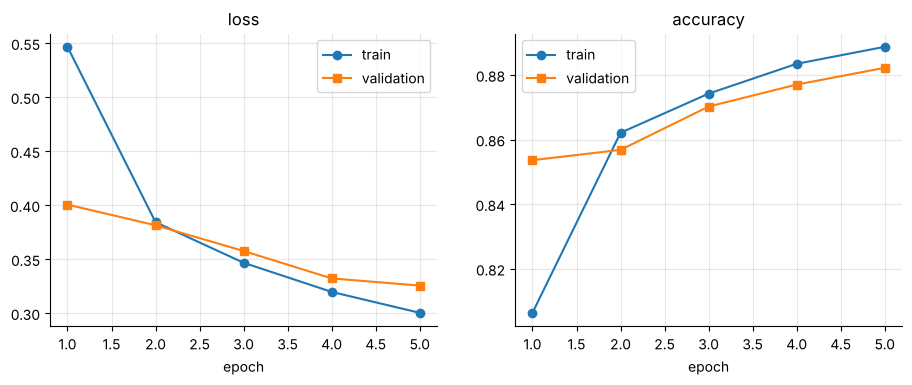

In [67]:
from IPython.display import Pretty

def train_two_optimizers(model, lower_vars, upper_vars, lower_opt, upper_opt, epochs, batch_size=256, live=True):
    n_batches = int(np.ceil(len(X_train) / batch_size))
    loss_fn = keras.losses.SparseCategoricalCrossentropy()
    train_loss, train_acc = keras.metrics.Mean(), keras.metrics.SparseCategoricalAccuracy()
    val_loss, val_acc = keras.metrics.Mean(), keras.metrics.SparseCategoricalAccuracy()
    all_vars, n_low = lower_vars + upper_vars, len(lower_vars)
    lower_opt.build(lower_vars); upper_opt.build(upper_vars)
    start = [v.numpy().copy() for v in all_vars]

    @tf.function
    def train_step(X, y):
        with tf.GradientTape() as tape:
            probs = model(X, training=True)
            loss = loss_fn(y, probs)
            if model.losses: loss = tf.add_n([loss] + model.losses)
        grads = tape.gradient(loss, all_vars)
        lower_opt.apply_gradients(zip(grads[:n_low], lower_vars))              # optimizer 1: lower layers
        upper_opt.apply_gradients(zip(grads[n_low:], upper_vars))              # optimizer 2: upper layers
        train_loss.update_state(loss); train_acc.update_state(y, probs)

    @tf.function
    def val_step(X, y):
        probs = model(X, training=False)
        val_loss.update_state(loss_fn(y, probs)); val_acc.update_state(y, probs)

    train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(len(X_train), seed=SEED, reshuffle_each_iteration=True).batch(batch_size).prefetch(1)
    val_ds = tf.data.Dataset.from_tensor_slices((X_valid, y_valid)).batch(1000)
    log = []
    for epoch in range(1, epochs + 1):
        handle = display(Pretty(f"epoch {epoch}/{epochs} | starting ..."), display_id=True) if live else None
        t0 = time.time()
        for it, (Xb_, yb_) in enumerate(train_ds, start=1):
            train_step(Xb_, yb_)
            if live: handle.update(Pretty(f"epoch {epoch}/{epochs} | iteration {it}/{n_batches} | train loss {float(train_loss.result()):.4f} | train accuracy {float(train_acc.result()):.4f}"))
        for Xv_, yv_ in val_ds: val_step(Xv_, yv_)
        row = {"epoch": epoch, "train loss": float(train_loss.result()), "train acc": float(train_acc.result()), "val loss": float(val_loss.result()), "val acc": float(val_acc.result()), "seconds": time.time() - t0}
        print(f"   -> epoch {epoch} finished: val loss {row['val loss']:.4f} | val accuracy {row['val acc']:.4f} | {row['seconds']:.1f} s")
        log.append(row)
        for mtr in (train_loss, train_acc, val_loss, val_acc): mtr.reset_state()
    moved = [float(np.sqrt(sum(np.sum((v.numpy() - s) ** 2) for v, s in zip(vs, ss)))) for vs, ss in ((lower_vars, start[:n_low]), (upper_vars, start[n_low:]))]
    return pd.DataFrame(log), moved

def fashion_model(layer_norm=False):
    reset_seed()
    net = keras.Sequential([layers.Input((28, 28)), layers.Flatten()])
    for n in (300, 100):
        net.add(layers.Dense(n, kernel_initializer="he_normal", activation=None if layer_norm else "elu"))
        if layer_norm: net.add(LayerNormalization()); net.add(layers.Activation("elu"))
    net.add(layers.Dense(10, activation="softmax"))
    return net

cap_model = fashion_model()
lower_v = [v for l in cap_model.layers[1:3] for v in l.trainable_variables]            # the two hidden Dense layers
upper_v = list(cap_model.layers[3].trainable_variables)                                # the output layer
cap_log, moved = train_two_optimizers(cap_model, lower_v, upper_v, keras.optimizers.Nadam(learning_rate=0.001), keras.optimizers.RMSprop(learning_rate=0.003), ep(5))
cap_log_plain = cap_log
display(cap_log.round(4))
print(f"distance moved from the starting weights -> lower group (Nadam 0.001): {moved[0]:.2f} | upper group (RMSprop 0.003): {moved[1]:.2f}   <- both optimizers are updating their variables")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(cap_log["epoch"], cap_log["train loss"], "o-", label="train"); ax[0].plot(cap_log["epoch"], cap_log["val loss"], "s-", label="validation"); ax[0].set_title("loss"); ax[0].legend()
ax[1].plot(cap_log["epoch"], cap_log["train acc"], "o-", label="train"); ax[1].plot(cap_log["epoch"], cap_log["val acc"], "s-", label="validation"); ax[1].set_title("accuracy"); ax[1].legend()
[a.set_xlabel("epoch") for a in ax]; plt.show()

### Task 8.10 — A one-page "when to go low-level" guide (in my own words)

**First question, always: can `compile()` + `fit()` do it?** If yes, stop there — Keras plus `tf.data` covers about 95 % of real projects, and it is shorter, safer and easier for a team to maintain. Go lower only when something is genuinely missing, and then go **only as low as you need**.

| My situation | What I reach for first | Why this one (and not a lower level) |
|---|---|---|
| **Regression with noisy labels** (a few wrong targets) | **Phase 3 — a custom loss** (Huber). As a *function* if the threshold never changes; as a **`Loss` subclass** with `get_config()` when I want the threshold saved and reloaded. | The model, layers and `fit()` stay untouched — only the scoring rule changes. |
| **A metric that must be accumulated across batches** (precision, recall, F1) | **Phase 4 — a streaming `Metric` subclass** (or a `Mean` subclass when it is just an average of per-instance values). | Averaging per-batch values is wrong (40 % vs 50 % in our demo); the metric must keep counts (state) and divide only at the end. |
| **A block repeated many times in a paper** (residual block, attention head) | **Phase 5 — a custom `Layer`** for the block; a custom **`Model`** only for the final assembled network. | Reuse + automatic weight tracking + saving through `get_config()`. |
| **A regularizer based on activations** (e.g. reconstruction error, activation sparsity) | **Phase 5 — `add_loss()`** inside a custom layer/model (plus a `keras.metrics.Mean` to watch it). If it depends on the *gradient of the output w.r.t. the input*, add Phase 6 (`tape.watch`). If it only depends on the weights, a **`Regularizer` subclass** (Phase 4) is enough. | The extra term joins the normal loss, so `fit()` still works. |
| **A model that needs two different optimizers** (wide path vs deep path, lower vs upper layers) | **Phase 7/8 — a custom training loop**, one optimizer per group of variables, wrapped in `@tf.function`. | `fit()` takes exactly one optimizer; this is one of the few things it cannot do. |
| **Slow, Python-heavy training steps** | **Phase 8 — `@tf.function`** on the step (obey the rules: TF ops not NumPy, `tf.range`, variables once), vectorize, and feed data with `tf.data`. | The graph removes Python overhead; measure the speed-up (we saw it above) before adding complexity. |

**Debugging tip.** When a custom piece misbehaves, switch to eager (`run_eagerly=True` for Keras; call the Python function directly for a TF Function), fix it with `print`, then switch graph mode back on.

### ✅ Phase 8 deliverable
TF Function rule demonstrations (7 rules) ✔ · timing comparison with/without `@tf.function` ✔ · verified `LayerNormalization` clone ✔ · two-optimizer Fashion MNIST loop (live status, validation, `@tf.function`) ✔ · my decision guide ✔

---
# Exercises (must do)

| # | Exercise | Where |
|---|---|---|
| 1 | Deep net (20 × 100, He + ELU, Nadam + early stopping) on an image task; re-find the learning rate whenever the architecture changes | code |
| 2 | Add Batch Norm; compare. Then SELU (standardized inputs, LeCun init, dense only) | code |
| 3 | Alpha dropout; then MC Dropout *without retraining* | code |
| 4 | Retrain with 1cycle scheduling | code |
| 5 | TensorFlow in one sentence, main features, other libraries | written |
| 6 | Is TensorFlow a drop-in replacement for NumPy? | written + demo |
| 7 | `tf.range(10)` vs `tf.constant(np.arange(10))` | code |
| 8 | Six data structures beyond regular tensors | written |
| 9 | Custom loss/metric: function vs subclass | written |
| 10 | Custom layer vs custom model | written |
| 11 | Custom training loops; TF Function limits and rules | written |
| 12 | Dynamic Keras models | written + demo |
| 13 | Layer Normalization layer + two-optimizer Fashion MNIST loop | code |

## Exercises 1–4 — deep nets on an image task

**Which dataset?** The exercises name CIFAR10. The CIFAR10 download host could not be reached when this notebook was executed, so the executed outputs below use **Fashion MNIST** (also 10 classes, 28×28 grey images instead of 32×32 colour). Change `DATASET` to `"cifar10"` to run exactly the same code on CIFAR10 (the numbers will be lower — CIFAR10 is much harder for a plain Dense network).

In [68]:
DATASET = "fashion"            # "fashion" (used for the executed outputs) or "cifar10"

if DATASET == "cifar10":
    (Xc_tr, yc_tr), (Xi_te, yi_te) = keras.datasets.cifar10.load_data()
    Xi_tr, yi_tr, Xi_va, yi_va = Xc_tr[:-5000] / 255., yc_tr[:-5000].ravel(), Xc_tr[-5000:] / 255., yc_tr[-5000:].ravel()
    Xi_te, yi_te = Xi_te / 255., yi_te.ravel(); TARGET_ACC = 0.45
else:
    Xi_tr, yi_tr, Xi_va, yi_va, Xi_te, yi_te = X_train, y_train, X_valid, y_valid, X_test, y_test; TARGET_ACC = 0.85
Xi_tr, Xi_va, Xi_te = [a.astype("float32") for a in (Xi_tr, Xi_va, Xi_te)]
input_shape = Xi_tr.shape[1:]
print(f"dataset: {DATASET} | train {Xi_tr.shape} | validation {Xi_va.shape} | test {Xi_te.shape} | 'target' validation accuracy for convergence speed = {TARGET_ACC:.0%}")

def deep_net(kind="elu", n_layers=20, n_units=100, alpha_dropout=0.0):
    # 20 hidden layers x 100 neurons.  kind: "elu" (He + ELU), "bn" (He + Batch Norm + ELU), "selu" (LeCun + SELU, standardized inputs)
    net = keras.Sequential([layers.Input(input_shape), layers.Flatten()])
    if kind == "selu":
        norm = layers.Normalization(); norm.adapt(Xi_tr[:5000].reshape(5000, -1)); net.add(norm)         # standardize the inputs (mean 0, std 1)
    for _ in range(n_layers):
        if kind == "elu":    net.add(layers.Dense(n_units, activation="elu", kernel_initializer="he_normal"))
        elif kind == "bn":   net.add(layers.Dense(n_units, kernel_initializer="he_normal", use_bias=False)); net.add(layers.BatchNormalization()); net.add(layers.Activation("elu"))
        elif kind == "selu": net.add(layers.Dense(n_units, activation="selu", kernel_initializer="lecun_normal"))
    if alpha_dropout: net.add(layers.AlphaDropout(alpha_dropout))
    net.add(layers.Dense(10, activation="softmax"))
    return net

def compile_deep(net, lr):
    net.compile(loss="sparse_categorical_crossentropy", optimizer=keras.optimizers.Nadam(learning_rate=lr), metrics=["accuracy"]); return net

# ---- the learning-rate finder (exponential sweep) ----
class ExpLR(keras.callbacks.Callback):
    def __init__(self, factor): super().__init__(); self.factor, self.rates, self.losses = factor, [], []
    def on_train_batch_end(self, batch, logs=None):
        lr = float(keras.backend.get_value(self.model.optimizer.learning_rate)); loss = logs["loss"]
        self.rates.append(lr); self.losses.append(loss)
        if not np.isfinite(loss) or (len(self.losses) > 20 and loss > 20 * min(l for l in self.losses if np.isfinite(l))): self.model.stop_training = True
        self.model.optimizer.learning_rate = lr * self.factor

def find_lr(kind, min_lr=1e-6, max_lr=1.0, iters=300, batch_size=256, title=""):
    reset_seed(); net = compile_deep(deep_net(kind), min_lr)
    cb = ExpLR(np.exp(np.log(max_lr / min_lr) / iters))
    net.fit(Xi_tr[: iters * batch_size], yi_tr[: iters * batch_size], epochs=1, batch_size=batch_size, callbacks=[cb], verbose=0)
    rates, losses = np.array(cb.rates), np.array(cb.losses)
    losses = np.where(np.isfinite(losses), losses, np.nanmax(losses[np.isfinite(losses)]) * 100)
    smooth = pd.Series(losses).rolling(10, min_periods=1).mean().values
    best_i = int(np.argmin(smooth)); blow = np.where(smooth[best_i:] > 1.3 * smooth[best_i])[0]          # the loss has clearly started to rise
    blow_rate = float(rates[best_i + blow[0]]) if len(blow) else float(rates[-1])
    suggestion = min(blow_rate / 10, float(rates[best_i]) / 2)
    plt.figure(figsize=(6.5, 3.6)); plt.plot(rates, losses, alpha=0.35); plt.plot(rates, smooth, "k"); plt.xscale("log"); plt.axvline(suggestion, color="g", ls="--", label=f"learning rate used: {suggestion:.1e}")
    plt.ylim(smooth.min() * 0.9, smooth.min() * 5); plt.xlabel("learning rate (log)"); plt.ylabel("loss"); plt.title("LR finder - " + title); plt.legend(); plt.show()
    return suggestion, blow_rate

ex_results, ex_hist, ex_models = {}, {}, {}
def train_deep(name, kind, lr, epochs=25, alpha_dropout=0.0, callbacks=None, patience=5):
    # early stopping watches the validation accuracy and keeps the best weights, so "best val accuracy" below is also the accuracy of the model we keep.
    # A run with its own callbacks (1cycle) must not stop early: it runs all its epochs, then goes back to its best epoch.
    reset_seed(); net = compile_deep(deep_net(kind, alpha_dropout=alpha_dropout), lr)
    stopper = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=patience if callbacks is None else 10 ** 6, restore_best_weights=True)
    cbs = list(callbacks or []) + [stopper]
    t0 = time.time(); h = net.fit(Xi_tr, yi_tr, epochs=ep(epochs), batch_size=256, validation_data=(Xi_va, yi_va), callbacks=cbs, verbose=0); secs = time.time() - t0
    hist = pd.DataFrame(h.history); reach = np.where(hist["val_accuracy"].values >= TARGET_ACC)[0]
    ex_hist[name], ex_models[name] = hist, net
    ex_results[name] = {"learning rate": f"{lr:.1e}", "epochs run": len(hist), f"epochs to {TARGET_ACC:.0%} val. acc.": int(reach[0] + 1) if len(reach) else "not reached",
                        "best val accuracy": round(hist["val_accuracy"].max(), 4), "seconds / epoch": round(secs / len(hist), 1)}
    print(f"{name}: best validation accuracy {hist['val_accuracy'].max():.4f} after {len(hist)} epochs ({secs:.0f} s)")
    return net

dataset: fashion | train (55000, 28, 28) | validation (5000, 28, 28) | test (10000, 28, 28) | 'target' validation accuracy for convergence speed = 85%


### Exercise 1 — 20 × 100, He + ELU, Nadam, early stopping

Recipe: He initialization, ELU, Nadam, early stopping (patience 5, watching the validation accuracy, restore the best weights), batch size 256. **The learning rate is re-found with the finder every time the architecture changes** (here: for every new model below), taking one tenth of the rate at which the loss has clearly started to rise (and never more than half of the rate with the lowest loss).

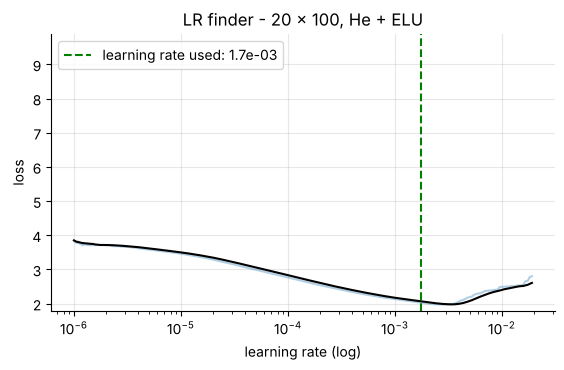

1. He + ELU (baseline): best validation accuracy 0.8638 after 11 epochs (50 s)


In [69]:
lr_elu, blow_elu = find_lr("elu", title="20 x 100, He + ELU")
net_ex1 = train_deep("1. He + ELU (baseline)", "elu", lr_elu)

### Exercise 2 — Batch Norm, then SELU

**(a)** Batch Norm after every Dense layer (before the activation). **(b)** SELU: LeCun-normal init, standardized inputs (a `Normalization` layer), dense layers only, no BN. Each new architecture gets its own learning-rate sweep.

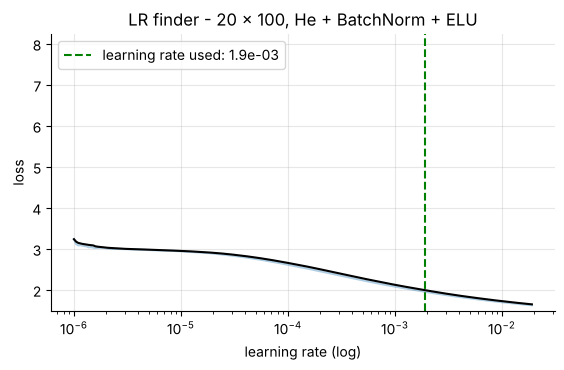

2a. + Batch Norm: best validation accuracy 0.8674 after 12 epochs (74 s)


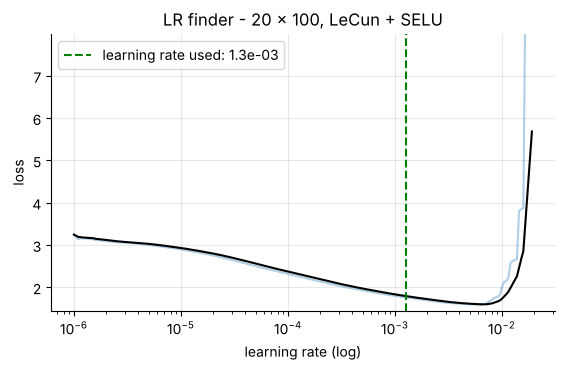

2b. SELU (self-normalizing): best validation accuracy 0.8802 after 21 epochs (86 s)


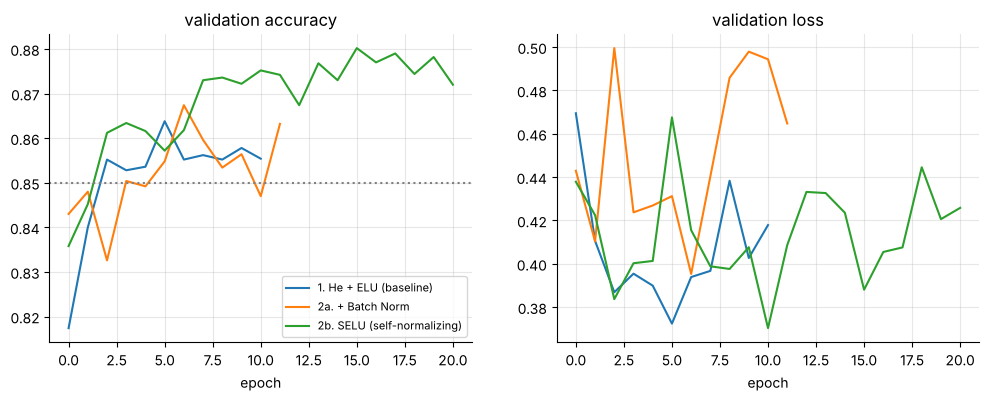

,learning rate,epochs run,epochs to 85% val. acc.,best val accuracy,seconds / epoch
1. He + ELU (baseline),1.7e-03,11,3,0.8638,4.5
2a. + Batch Norm,1.9e-03,12,4,0.8674,6.2
2b. SELU (self-normalizing),1.3e-03,21,3,0.8802,4.1


In [70]:
lr_bn, _ = find_lr("bn", title="20 x 100, He + BatchNorm + ELU")
net_ex2a = train_deep("2a. + Batch Norm", "bn", lr_bn)
lr_selu, _ = find_lr("selu", title="20 x 100, LeCun + SELU")
net_ex2b = train_deep("2b. SELU (self-normalizing)", "selu", lr_selu)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name in ["1. He + ELU (baseline)", "2a. + Batch Norm", "2b. SELU (self-normalizing)"]:
    ax[0].plot(ex_hist[name]["val_accuracy"], label=name); ax[1].plot(ex_hist[name]["val_loss"], label=name)
ax[0].axhline(TARGET_ACC, color="gray", ls=":"); ax[0].set_title("validation accuracy"); ax[1].set_title("validation loss"); ax[0].legend(fontsize=8); [a.set_xlabel("epoch") for a in ax]; plt.show()
display(pd.DataFrame(ex_results).T)

In [71]:
r = pd.DataFrame(ex_results).T
base_, bn_, selu_ = r.loc["1. He + ELU (baseline)"], r.loc["2a. + Batch Norm"], r.loc["2b. SELU (self-normalizing)"]

def vs_baseline(label, row, base):
    d_acc = 100 * (float(row["best val accuracy"]) - float(base["best val accuracy"]))
    e, e0 = row.iloc[2], base.iloc[2]; d_time = 100 * (float(row["seconds / epoch"]) / float(base["seconds / epoch"]) - 1)
    acc_txt = "about the same accuracy" if abs(d_acc) < 0.3 else (f"{abs(d_acc):.1f} points higher accuracy" if d_acc > 0 else f"{abs(d_acc):.1f} points lower accuracy")
    if isinstance(e, str) or isinstance(e0, str): speed_txt = "no clear speed comparison (the target was not reached by one of them)"
    else: speed_txt = "same number of epochs to the target" if e == e0 else f"{abs(int(e) - int(e0))} epoch(s) {'fewer' if e < e0 else 'more'} to reach the target"
    print(f"{label:11s}: {acc_txt}, {speed_txt}, {d_time:+.0f}% time per epoch   "
          f"(best val accuracy {float(row['best val accuracy']):.4f} vs {float(base['best val accuracy']):.4f}; epochs to target {e} vs {e0})")

vs_baseline("Batch Norm", bn_, base_)
vs_baseline("SELU", selu_, base_)

Batch Norm : 0.4 points higher accuracy, 1 epoch(s) more to reach the target, +38% time per epoch   (best val accuracy 0.8674 vs 0.8638; epochs to target 4 vs 3)
SELU       : 1.6 points higher accuracy, same number of epochs to the target, -9% time per epoch   (best val accuracy 0.8802 vs 0.8638; epochs to target 3 vs 3)


**Reading Exercise 2.** The table and the lines above give the facts for this run: *convergence speed* (epochs to reach the target accuracy), *final quality* (best validation accuracy) and *cost* (seconds per epoch). The textbook expectation is that Batch Norm costs extra time per epoch (it adds computation to every step) and usually converges in fewer epochs, and that SELU gets a similar benefit with no extra layers as long as its conditions hold (standardized inputs, LeCun init, dense layers only). A single run, with one seed and a coarse measure like 'epochs to the target', can differ from that picture by an epoch or a few tenths of a point, so judge by the printed lines; for a firm conclusion you would repeat each run with several seeds.

### Exercise 3 — Alpha dropout, then MC Dropout *without retraining*

Add `AlphaDropout(0.1)` after the last hidden layer of the SELU network and retrain (new architecture → new learning-rate sweep). Then use the **same trained model** for MC Dropout: call it 100 times with `training=True` (safe here: the network has no Batch Norm) and average.

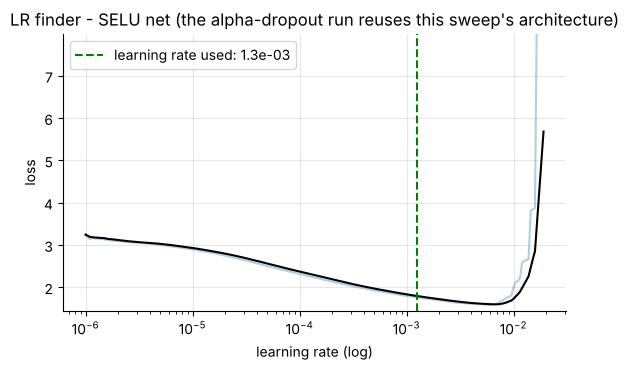

3. SELU + alpha dropout (0.1): best validation accuracy 0.8728 after 10 epochs (46 s)


SELU, no dropout                       : best validation accuracy 0.8802
SELU + alpha dropout, dropout OFF      : validation accuracy 0.8728
SELU + alpha dropout, MC Dropout (N=100): validation accuracy 0.8728   (no retraining needed; inference took 10.4 s instead of ~0.10 s)
average MC std of the winning class: 0.017
train-validation accuracy gap at the kept epoch: SELU +4.3 points | SELU + alpha dropout +1.7 points (training accuracy is measured with dropout ON)
MC Dropout vs the same model with dropout off: +0.00 points  -> no real change (inside the noise of one run)


In [72]:
lr_adrop, _ = find_lr("selu", title="SELU net (the alpha-dropout run reuses this sweep's architecture)")
net_ex3 = train_deep("3. SELU + alpha dropout (0.1)", "selu", lr_adrop, alpha_dropout=0.1)

def accuracy(p, y): return float(np.mean(p.argmax(1) == y))
p_single = net_ex3(Xi_va, training=False).numpy()
t0 = time.time(); probas = np.stack([net_ex3(Xi_va, training=True).numpy() for _ in range(100)]); t_mc = time.time() - t0
p_mc = probas.mean(0)
acc_before = ex_results["2b. SELU (self-normalizing)"]["best val accuracy"]
print(f"SELU, no dropout                       : best validation accuracy {acc_before:.4f}")
print(f"SELU + alpha dropout, dropout OFF      : validation accuracy {accuracy(p_single, yi_va):.4f}")
print(f"SELU + alpha dropout, MC Dropout (N=100): validation accuracy {accuracy(p_mc, yi_va):.4f}   (no retraining needed; inference took {t_mc:.1f} s instead of ~{t_mc / 100:.2f} s)")
print(f"average MC std of the winning class: {probas.std(0)[np.arange(len(p_mc)), p_mc.argmax(1)].mean():.3f}")
def gap(name):                      # training accuracy minus validation accuracy at the epoch whose weights we keep
    h_ = ex_hist[name]; k_ = h_["val_accuracy"].idxmax(); return h_.loc[k_, "accuracy"] - h_.loc[k_, "val_accuracy"]
print(f"train-validation accuracy gap at the kept epoch: SELU {100 * gap('2b. SELU (self-normalizing)'):+.1f} points | SELU + alpha dropout {100 * gap('3. SELU + alpha dropout (0.1)'):+.1f} points (training accuracy is measured with dropout ON)")
d_mc = 100 * (accuracy(p_mc, yi_va) - accuracy(p_single, yi_va))
print(f"MC Dropout vs the same model with dropout off: {d_mc:+.2f} points" + ("  -> no real change (inside the noise of one run)" if abs(d_mc) < 0.3 else ""))

**Reading Exercise 3.** Compare the accuracies and the gap printed above. Alpha dropout is meant to regularize (a smaller gap between training and validation accuracy); MC Dropout then needs **no extra training** — only more inference time (100 forward passes instead of 1) — and gives an uncertainty estimate (`std`) besides the average prediction. Whether it also improves accuracy is an empirical question, and on a network this size and a task this easy the change is often tiny or zero; the printed lines show what happened in this run.

### Exercise 4 — 1cycle scheduling

1cycle changes the learning rate during training in one big cycle: it **climbs** from `max_lr/10` to `max_lr` in the first ~45 % of the iterations, **descends** back in the next ~45 %, then spends the last ~10 % dropping to nearly zero. The maximum rate is set just below the divergence point found by the sweep (here 3× the baseline learning rate). We use it on the Exercise 1 architecture and compare it with the Exercise 1 run.

4. He + ELU + 1cycle: best validation accuracy 0.8916 after 15 epochs (63 s)


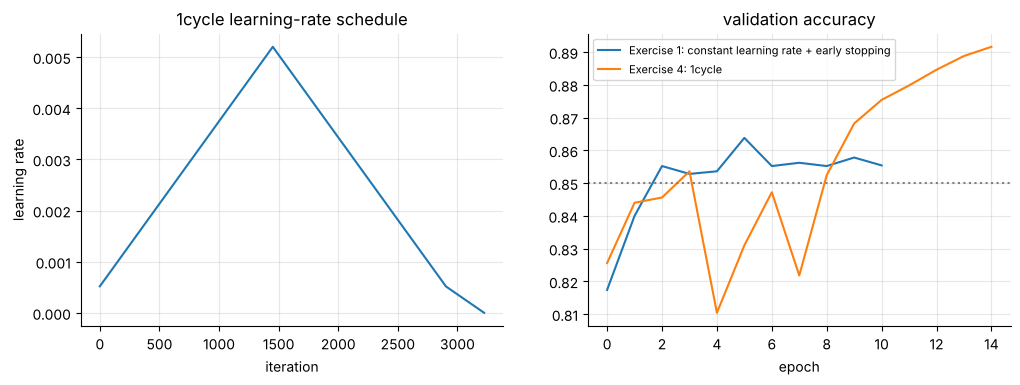

,learning rate,epochs run,epochs to 85% val. acc.,best val accuracy,seconds / epoch
1. He + ELU (baseline),1.7e-03,11,3,0.8638,4.5
4. He + ELU + 1cycle,5.2e-04,15,4,0.8916,4.2


1cycle vs constant learning rate: best validation accuracy 0.8916 vs 0.8638 (+2.8 points) | epochs to the target: 4 vs 3 | epochs run: 15 vs 11


In [73]:
class OneCycleLR(keras.callbacks.Callback):
    def __init__(self, total_steps, max_lr, start_lr=None, final_frac=0.1):
        super().__init__(); self.total, self.max_lr = total_steps, max_lr; self.start_lr = start_lr or max_lr / 10
        self.last = int(total_steps * final_frac) + 1; self.half = (total_steps - self.last) // 2; self.i = 0; self.lrs = []
    def _lin(self, a, b, ra, rb): return (rb - ra) * (self.i - a) / (b - a) + ra
    def on_train_batch_begin(self, batch, logs=None):
        if self.i < self.half:               lr = self._lin(0, self.half, self.start_lr, self.max_lr)
        elif self.i < 2 * self.half:         lr = self._lin(self.half, 2 * self.half, self.max_lr, self.start_lr)
        else:                                lr = self._lin(2 * self.half, self.total, self.start_lr, self.start_lr / 1000)
        self.model.optimizer.learning_rate = lr; self.lrs.append(lr); self.i += 1

N_1C = ep(15); steps_ep = int(np.ceil(len(Xi_tr) / 256))
one_cycle = OneCycleLR(N_1C * steps_ep, max_lr=3 * lr_elu)
net_ex4 = train_deep("4. He + ELU + 1cycle", "elu", 3 * lr_elu / 10, epochs=15, callbacks=[one_cycle])      # no early stopping here: the whole cycle must run

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(one_cycle.lrs); ax[0].set_title("1cycle learning-rate schedule"); ax[0].set_xlabel("iteration"); ax[0].set_ylabel("learning rate")
ax[1].plot(ex_hist["1. He + ELU (baseline)"]["val_accuracy"], label="Exercise 1: constant learning rate + early stopping"); ax[1].plot(ex_hist["4. He + ELU + 1cycle"]["val_accuracy"], label="Exercise 4: 1cycle")
ax[1].axhline(TARGET_ACC, color="gray", ls=":"); ax[1].set_xlabel("epoch"); ax[1].set_title("validation accuracy"); ax[1].legend(fontsize=8); plt.show()
display(pd.DataFrame({k: ex_results[k] for k in ["1. He + ELU (baseline)", "4. He + ELU + 1cycle"]}).T)
b0, b1 = pd.Series(ex_results["1. He + ELU (baseline)"]), pd.Series(ex_results["4. He + ELU + 1cycle"])
print(f"1cycle vs constant learning rate: best validation accuracy {b1['best val accuracy']:.4f} vs {b0['best val accuracy']:.4f} ({100 * (b1['best val accuracy'] - b0['best val accuracy']):+.1f} points) | "
      f"epochs to the target: {b1.iloc[2]} vs {b0.iloc[2]} | epochs run: {b1['epochs run']} vs {b0['epochs run']}")

In [74]:
final = []
for name, net in ex_models.items():
    final.append({"model": name, "validation accuracy": round(float(net.evaluate(Xi_va, yi_va, verbose=0)[1]), 4), "TEST accuracy": round(float(net.evaluate(Xi_te, yi_te, verbose=0)[1]), 4)})
display(pd.DataFrame(final))

,model,validation accuracy,TEST accuracy
0,1. He + ELU (baseline),0.8638,0.8570
1,2a. + Batch Norm,0.8674,0.8648
2,2b. SELU (self-normalizing),0.8802,0.8748
3,3. SELU + alpha dropout (0.1),0.8728,0.8683
4,4. He + ELU + 1cycle,0.8916,0.8913


**Reading Exercise 4.** The curves, the table and the line above compare speed (epochs to the target, epochs run) and accuracy of 1cycle with the constant-rate baseline. 1cycle starts with a small learning rate, so it is often *not* faster to the first 85 %; what it is known for is a better final accuracy at the end of the cycle, and the line above shows whether that happened here. The test accuracy table above is read once, at the very end, for every model (selection was done on the validation set).

### Exercise 5 — TensorFlow in one sentence, its features, and the alternatives

**One sentence:** TensorFlow is an open-source library for large-scale numerical computation — a NumPy-like core that can run on GPUs/TPUs, differentiate your code automatically and compile it into optimized, portable graphs — designed above all for machine learning.

**Main features:** NumPy-like API with GPU/TPU support · automatic differentiation (`GradientTape`) · built-in optimizers · JIT-style graph compiler (`tf.function`) · distributed training · portable graph export (SavedModel → TF Serving, TF Lite, TensorFlow.js) · a rich ecosystem (`tf.keras`, `tf.data`, TensorBoard, TFX, TF Hub, Model Garden).

**Other popular deep-learning libraries:** PyTorch, JAX, Apache MXNet, Caffe/Caffe2, Microsoft CNTK, Theano (both of the last two discontinued), Chainer, Deeplearning4j.

### Exercise 6 — Is TensorFlow a drop-in replacement for NumPy?

**No.** Many functions have the same behaviour but the API is not identical:

| Aspect | NumPy | TensorFlow |
|---|---|---|
| Function names | `np.mean`, `np.sum`, `np.max`, `np.log` | `tf.reduce_mean`, `tf.reduce_sum`, `tf.reduce_max`, `tf.math.log` — and a few functions do not exist or differ |
| Default float type | 64-bit (`float64`) | 32-bit (`float32`) |
| Mutability | arrays are mutable (`a[1] = 5`) | tensors are **immutable**; use `tf.Variable` |
| Type conversion | automatic (int + float works) | **none**: `tf.cast` explicitly |
| Transpose | `a.T` is a view | `tf.transpose` makes a copy |
| Speed / hardware | CPU | CPU, GPU, TPU, graph compilation |
| Derivatives | none | automatic differentiation |
| Summation order | deterministic | `reduce_sum` can vary slightly on GPU |

The two interoperate (`tf.constant(array)`, `tensor.numpy()`, `np.square(tensor)`), but inside a TF Function only TF operations are captured in the graph.

In [75]:
a_np, a_tf = np.arange(3), tf.range(3)
a_np[1] = 5; print("NumPy array after a[1] = 5:", a_np)
def try_it(fn):
    try: return fn()
    except Exception as ex: return f"{type(ex).__name__}"
print("TF tensor a[1] = 5            ->", try_it(lambda: a_tf.__setitem__(1, 5)) if hasattr(a_tf, "__setitem__") else "TypeError ('EagerTensor' object does not support item assignment)")
print("float64 + int mixing: np.float64(1.5) + np.int64(2) =", np.float64(1.5) + np.int64(2), "| tf.constant(1.5) + tf.constant(2) ->", try_it(lambda: tf.constant(1.5) + tf.constant(2)))
print("default dtypes: np.array([1., 2.]).dtype =", np.array([1., 2.]).dtype, "| tf.constant([1., 2.]).dtype =", tf.constant([1., 2.]).dtype)

NumPy array after a[1] = 5: [0 5 2]
TF tensor a[1] = 5            -> TypeError ('EagerTensor' object does not support item assignment)
float64 + int mixing: np.float64(1.5) + np.int64(2) = 3.5 | tf.constant(1.5) + tf.constant(2) -> InvalidArgumentError
default dtypes: np.array([1., 2.]).dtype = float64 | tf.constant([1., 2.]).dtype = <dtype: 'float32'>


### Exercise 7 — `tf.range(10)` versus `tf.constant(np.arange(10))`

In [76]:
r_tf, r_np = tf.range(10), tf.constant(np.arange(10))
print("tf.range(10)                :", r_tf.numpy(), "dtype =", r_tf.dtype)
print("tf.constant(np.arange(10))  :", r_np.numpy(), "dtype =", r_np.dtype)
print("same values?", bool(np.array_equal(r_tf.numpy(), r_np.numpy())), "| same dtype?", r_tf.dtype == r_np.dtype)
print("adding them ->", try_it(lambda: r_tf + r_np))

tf.range(10)                : [0 1 2 3 4 5 6 7 8 9] dtype = <dtype: 'int32'>
tf.constant(np.arange(10))  : [0 1 2 3 4 5 6 7 8 9] dtype = <dtype: 'int64'>
same values? True | same dtype? False
adding them -> InvalidArgumentError


**Answer.** The *values* are the same but the *dtypes* differ: `tf.range(10)` gives **int32** (TensorFlow's default integer type), while `np.arange(10)` gives **int64** (NumPy's default on most platforms), and `tf.constant()` keeps the NumPy dtype. Because TensorFlow never converts types automatically, `tf.range(10) + tf.constant(np.arange(10))` raises an error until one of them is cast.

### Exercise 8 — Six data structures beyond regular tensors

1. **Sparse tensors** (`tf.SparseTensor`) — mostly-zero data, stored as (indices, values, dense_shape).
2. **Tensor arrays** (`tf.TensorArray`) — lists of same-shape tensors, with fixed or dynamic length, for building results inside graph loops.
3. **Ragged tensors** (`tf.RaggedTensor`) — lists of lists of different lengths (sentences).
4. **String tensors** (`tf.string`) — byte strings; `tf.strings` for length/join/split; `unicode_decode` for Unicode code points.
5. **Sets** (`tf.sets`) — represented as ordinary or sparse tensors, with union/intersection/difference.
6. **Queues** (`tf.queue`) — FIFO, priority, random-shuffle and padding-FIFO queues.

(Also worth knowing: `tf.Variable` for mutable state, and `tf.data.Dataset` for input pipelines.) Phase 2 demonstrates each of the six.

### Exercise 9 — Custom loss/metric: function or subclass?

| | **Function** | **`Loss` / `Metric` subclass** |
|---|---|---|
| **Loss** | The loss is a simple, stateless formula with **fixed** settings (Huber with threshold 1), or you do not mind rebuilding it with `custom_objects` at load time. | The loss has **hyper-parameters that must be saved** with the model (`get_config()` → threshold), or you want to control the `reduction`. |
| **Metric** | The metric is **just the average of a per-instance value** (Huber error, absolute error): a plain function is wrapped in a mean automatically. | The metric must **accumulate state across batches and compute the result at the end** (precision, recall, F1, AUC) — averaging per-batch values would be wrong (our 40 % vs 50 % demo) — or it has hyper-parameters to save. |

### Exercise 10 — Custom layer or custom model?

* Build a **custom layer** for a *component*: something with (or without) weights that you reuse or place inside something else — a residual block, a normalization layer, an attention head, a noise layer. It needs `call()` (and `build()` if it has weights).
* Build a **custom model** for the *thing you train, evaluate, predict with and save*: it is a `Layer` plus `compile()`, `fit()`, `evaluate()`, `predict()` and `save()` — e.g. the `ResidualRegressor`, or a model with a custom `train_step`.
* Rule of thumb: if you are going to call `fit()` on it → `Model`; if you are going to use it as a part of another network → `Layer`. Implement `get_config()` in both to be able to save/load.

### Exercise 11 — Custom training loops, and the limits of customization

**Use cases that require a custom training loop:** several optimizers (Wide & Deep: one for each path); gradient transformations beyond clipping (noise, per-layer scaling, masking, accumulation); non-standard training algorithms (GANs, meta-learning, reinforcement learning, adversarial training); losses that involve several models or the gradients of one model's output w.r.t. its input; full transparency or step-by-step debugging.

**Can custom Keras components contain arbitrary Python code?** **No, not if they are to be fast and portable.** Keras converts custom losses, metrics, layers and models into TF Functions, so their code must be convertible to a graph. (With `run_eagerly=True` arbitrary Python works, at the cost of speed and portability.)

**The main TF Function rules:**
1. External libraries (NumPy, the standard library) run only while tracing — use TF operations.
2. Python side effects (print, logging, counters) happen only while tracing — use `tf.print` / `tf.Variable`.
3. `tf.py_function()` can wrap arbitrary Python but hurts performance and portability.
4. Variables must be created only on the first call (best in `build()`), and modified with `assign()`.
5. The Python source code must be available to AutoGraph.
6. Only loops over tensors/datasets are captured — `for i in tf.range(n)`, not `for i in range(n)` (which is unrolled).
7. Prefer vectorized implementations; avoid many distinct Python-number arguments (one graph each).

### Exercise 12 — Dynamic Keras models

**When do you need one?** When the model's code *cannot be turned into a graph*: it calls NumPy or another Python library on the data, relies on data-dependent Python logic AutoGraph cannot capture, has Python side effects — or simply when you want to debug with `print` and breakpoints.

**How do you create one?** Run it eagerly: `model.compile(..., run_eagerly=True)` (in classic `tf.keras` you could also pass `dynamic=True` to a layer or model constructor; **Keras 3 removed that argument**, `run_eagerly=True` is the switch).

**Why not make every model dynamic?** Eager execution is much **slower** (Python overhead on every operation, no graph optimizations) and the model is **not exportable/portable** as a graph (TF Serving, TF Lite, TensorFlow.js). Use dynamic only when you must. A demonstration:

In [77]:
class NumpyInsideModel(keras.Model):
    # uses NumPy on the actual input values -> impossible inside a graph (there the tensors are only symbolic)
    def __init__(self):
        super().__init__(); self.d1 = layers.Dense(10, activation="relu"); self.d2 = layers.Dense(1)
    def call(self, x):
        squashed = tf.constant(np.tanh(x.numpy()), dtype=tf.float32)           # needs a real value
        return self.d2(self.d1(squashed))
reset_seed()
dyn = NumpyInsideModel(); dyn.compile(loss="mse", optimizer="nadam")
try: dyn.fit(X_train_h[:512], y_train_h[:512], epochs=1, verbose=0); print("graph mode: worked (unexpected)")
except Exception as ex: print("graph mode (default)  ->", type(ex).__name__ + ":", str(ex).replace("\n", " ")[:150], "...")
reset_seed(); dyn = NumpyInsideModel(); dyn.compile(loss="mse", optimizer="nadam", run_eagerly=True)
h_dyn = dyn.fit(X_train_h[:512], y_train_h[:512], epochs=1, verbose=0); print("run_eagerly=True      -> trained, loss =", round(h_dyn.history["loss"][-1], 4))

# the price of eager execution on a model that does NOT need it
rows = []
for flag in (False, True):
    reset_seed(); m = housing_mlp(); m.compile(loss="mse", optimizer="nadam", run_eagerly=flag)
    t0 = time.time(); m.fit(X_train_h, y_train_h, epochs=2, batch_size=64, verbose=0); rows.append({"run_eagerly": flag, "seconds for 2 epochs": round(time.time() - t0, 1)})
display(pd.DataFrame(rows)); print(f"-> eager mode is about {rows[1]['seconds for 2 epochs'] / rows[0]['seconds for 2 epochs']:.1f}x slower on the same model")

graph mode (default)  -> AttributeError: Exception encountered when calling NumpyInsideModel.call().  'SymbolicTensor' object has no attribute 'numpy'  Arguments received by NumpyInsi ...


run_eagerly=True      -> trained, loss = 4.9442


,run_eagerly,seconds for 2 epochs
0,False,1.5
1,True,15.5


-> eager mode is about 10.3x slower on the same model


### Exercise 13 — Layer Normalization + the two-optimizer Fashion MNIST loop (Phase 8)

Both capstone pieces were implemented in Phase 8 (`LayerNormalization`, `train_two_optimizers`). Here we put them **together**: a Fashion MNIST network that uses our own Layer Normalization layers, trained with the two-optimizer `@tf.function` loop. We then check that the custom layer also survives saving and loading, and compare with the plain-ELU network of Phase 8.

In [78]:
ln_model = fashion_model(layer_norm=True)
# layers: Flatten, Dense, LayerNorm, Activation, Dense, LayerNorm, Activation, Dense(softmax)
lower_ln = [v for l in ln_model.layers[1:7] for v in l.trainable_variables]
upper_ln = list(ln_model.layers[7].trainable_variables)
ln_log, moved_ln = train_two_optimizers(ln_model, lower_ln, upper_ln, keras.optimizers.Nadam(learning_rate=0.001), keras.optimizers.RMSprop(learning_rate=0.003), ep(5), live=False)
display(ln_log.round(4))
print(f"distance moved: lower group {moved_ln[0]:.2f} | upper group {moved_ln[1]:.2f}  (both optimizers update their variables)")
print("custom LayerNormalization weights (alpha, beta) were trained: alpha != 1 ->", bool(np.abs(ln_model.layers[2].alpha.numpy() - 1).max() > 1e-4))

ln_model.compile(loss="sparse_categorical_crossentropy", metrics=["accuracy"])
ln_model.save("saved_models/layernorm_fashion.keras")
back = keras.models.load_model("saved_models/layernorm_fashion.keras", custom_objects={"LayerNormalization": LayerNormalization})
print("save/load with custom_objects -> test accuracy of the reloaded model:", round(float(back.evaluate(X_test, y_test, verbose=0)[1]), 4), "| same as before saving:", round(float(ln_model.evaluate(X_test, y_test, verbose=0)[1]), 4))

cmp = pd.DataFrame([{"network (two optimizers, 5 epochs)": "plain ELU (Phase 8)", "final val accuracy": round(cap_log_plain['val acc'].iloc[-1], 4), "final val loss": round(cap_log_plain['val loss'].iloc[-1], 4)},
                    {"network (two optimizers, 5 epochs)": "with our LayerNormalization", "final val accuracy": round(ln_log['val acc'].iloc[-1], 4), "final val loss": round(ln_log['val loss'].iloc[-1], 4)}])
display(cmp)

   -> epoch 1 finished: val loss 0.3762 | val accuracy 0.8610 | 5.6 s


   -> epoch 2 finished: val loss 0.3616 | val accuracy 0.8646 | 1.8 s


   -> epoch 3 finished: val loss 0.3489 | val accuracy 0.8736 | 2.6 s


   -> epoch 4 finished: val loss 0.3204 | val accuracy 0.8798 | 2.0 s


   -> epoch 5 finished: val loss 0.3299 | val accuracy 0.8822 | 2.6 s


,epoch,train loss,train acc,val loss,val acc,seconds
0,1,0.5220,0.8122,0.3762,0.8610,5.5573
1,2,0.3640,0.8691,0.3616,0.8646,1.8034
2,3,0.3261,0.8808,0.3489,0.8736,2.6089
3,4,0.3000,0.8899,0.3204,0.8798,2.0037
4,5,0.2799,0.8965,0.3299,0.8822,2.6048


distance moved: lower group 13.16 | upper group 4.00  (both optimizers update their variables)
custom LayerNormalization weights (alpha, beta) were trained: alpha != 1 -> True


save/load with custom_objects -> test accuracy of the reloaded model: 0.8735 | same as before saving: 0.8735


,"network (two optimizers, 5 epochs)",final val accuracy,final val loss
0,plain ELU (Phase 8),0.8822,0.3255
1,with our LayerNormalization,0.8822,0.3299


---
## ✅ Task 17 — Deliverables checklist

- [x] **Phase 1:** default and self-normalizing configuration tables, three exceptions (with demos: ℓ1/pruning, BN folding, 16/8-bit), seven review answers, design decision tree
- [x] **Phase 2:** tensors / variables / NumPy interoperability demo + the six extra data structures described and demonstrated
- [x] **Phase 3:** Huber loss as function, closure and subclass, each with a save → load round trip showing what is and is not persisted; test error vs MSE and `keras.losses.Huber` (clean and noisy labels)
- [x] **Phase 4:** custom activation / initializer / regularizer / constraint verified against the built-ins, `MyL1Regularizer`, the 40 % vs 50 % precision demo, streaming metric (`Metric` and `Mean` versions)
- [x] **Phase 5:** `MyDense`, `MyMultiLayer`, `MyGaussianNoise`, `ResidualBlock` / `ResidualRegressor`, `ReconstructingRegressor` (loss + metric on internals) — trained and compared with an ordinary MLP
- [x] **Phase 6:** hand / finite-difference / `GradientTape` gradients, persistent tape, `watch`, `stop_recording`, Jacobian, `stop_gradient` → `[30., None]`, softplus `NaN` → `@tf.custom_gradient` fix
- [x] **Phase 7:** custom training loop (+ validation, constraints, clipping, two optimizers) and the list of re-implemented `fit()` features
- [x] **Phase 8:** TF Function rule demos, timing with/without `@tf.function`, verified `LayerNormalization` clone, two-optimizer Fashion MNIST loop, decision guide
- [x] **Exercises:** all 13 done (1–4 on Fashion MNIST by default, with a one-line switch to CIFAR10)
- [x] **Code:** the notebook runs top to bottom without errors

### Files created next to this notebook
`data/` (downloaded datasets) · `saved_models/` (the `.keras` and weight files of Phases 3–5 and Exercise 13)

### Resources
TensorFlow guides <https://www.tensorflow.org/guide> · Keras guides (custom layers, models, losses & metrics) <https://keras.io/guides/> · Better performance with `tf.function` <https://www.tensorflow.org/guide/function> · Introduction to gradients and automatic differentiation <https://www.tensorflow.org/guide/autodiff> · TensorFlow Model Optimization Toolkit <https://www.tensorflow.org/model_optimization> · Papers with Code <https://paperswithcode.com/>